In [2]:
import numpy, pandas, joblib, sklearn, matplotlib, seaborn, scipy;
print('All required libraries are installed');

All required libraries are installed


In [3]:
# ============================================================
# STEP 7: MODEL EVALUATION
# PART A: SETUP
# ============================================================

import json
import os
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import joblib
import sklearn

import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

from sklearn.model_selection import (
    KFold,
    cross_val_predict,
    cross_validate
)

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

from sklearn.base import clone


# Suppress FutureWarnings to keep notebook output readable.
warnings.filterwarnings("ignore", category=FutureWarning)

# Use a consistent plotting theme.
sns.set_theme(style="whitegrid")

# Find the project root relative to this notebook.
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

# Define important project directories.
DATA_DIR = PROJECT_ROOT / "data" / "processed"
MODELS_DIR = PROJECT_ROOT / "models"
REPORTS_DIR = PROJECT_ROOT / "reports"
FIGURES_DIR = REPORTS_DIR / "figures"

# Create the figures directory if it does not exist.
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Data directory:", DATA_DIR)
print("Models directory:", MODELS_DIR)
print("Figures directory:", FIGURES_DIR)
print("scikit-learn version:", sklearn.__version__)

Project root: d:\real-estate-price-prediction
Data directory: d:\real-estate-price-prediction\data\processed
Models directory: d:\real-estate-price-prediction\models
Figures directory: d:\real-estate-price-prediction\reports\figures
scikit-learn version: 1.9.1


In [5]:
# ============================================================
# LOAD FEATURE CONFIGURATION
# ============================================================

CONFIG_PATH = MODELS_DIR / "feature_config.json"

if not CONFIG_PATH.exists():
    raise FileNotFoundError(
        f"Feature configuration not found: {CONFIG_PATH}"
    )

with open(CONFIG_PATH, "r", encoding="utf-8") as file:
    cfg = json.load(file)

NUM = cfg["numeric_features"]
CAT = cfg["categorical_features"]

FEATURES = NUM + CAT

print("Numeric features:", len(NUM))
print(NUM)

print("\nCategorical features:", len(CAT))
print(CAT)

print("\nTotal features:", len(FEATURES))

Numeric features: 9
['bedroom_num', 'bathroom_num', 'balcony_num', 'floor_num', 'total_floor', 'total_landmark_count', 'area_sqft', 'latitude', 'longitude']

Categorical features: 6
['property_type', 'owntype', 'furnish', 'facing', 'age', 'locality_grouped']

Total features: 15


In [6]:
# ============================================================
# VALIDATE FEATURE CONFIGURATION
# ============================================================

assert len(NUM) == 9, "Unexpected number of numeric features"
assert len(CAT) == 6, "Unexpected number of categorical features"

assert len(FEATURES) == len(set(FEATURES)), (
    "Duplicate feature names found in configuration"
)

assert "price_lakhs" not in FEATURES, (
    "The target must not be included as a model input"
)

assert "log_price" not in FEATURES, (
    "The transformed target must not be included as a model input"
)

assert "prop_id" not in FEATURES, (
    "Property ID must not be used as a model input"
)

assert "price_per_sqft" not in FEATURES, (
    "price_per_sqft must not be included because it can leak target information"
)

print("Feature configuration validated successfully.")

Feature configuration validated successfully.


In [7]:
meta = json.load(open("../models/model_meta.json"))

assert meta["sklearn_version"] == sklearn.__version__

In [8]:
# ============================================================
# INSPECT MODEL METADATA
# ============================================================

metadata_files = [
    MODELS_DIR / "model_meta.json",
    MODELS_DIR / "selected_model_metadata.json",
    MODELS_DIR / "final_model_metadata.json",
    MODELS_DIR / "model_config.json",
]

found_metadata = False

for metadata_path in metadata_files:
    if metadata_path.exists():
        print(f"\n--- {metadata_path.name} ---")

        try:
            with open(metadata_path, "r", encoding="utf-8") as file:
                metadata = json.load(file)

            print(json.dumps(metadata, indent=2))
            found_metadata = True

        except json.JSONDecodeError:
            print("This file is not valid JSON.")

if not found_metadata:
    print("No matching metadata files were found.")


--- model_meta.json ---
{
  "sklearn_version": "1.9.1",
  "numeric_features": [
    "bedroom_num",
    "bathroom_num",
    "balcony_num",
    "floor_num",
    "total_floor",
    "total_landmark_count",
    "area_sqft",
    "latitude",
    "longitude"
  ],
  "categorical_features": [
    "property_type",
    "owntype",
    "furnish",
    "facing",
    "age",
    "locality_grouped"
  ],
  "target": "price_lakhs",
  "target_transform": "log1p / expm1",
  "train_rows": 5965,
  "models": [
    "Linear Regression",
    "Decision Tree",
    "Random Forest",
    "Gradient Boosting"
  ],
  "model_type": "TransformedTargetRegressor",
  "prediction_unit": "lakhs"
}

--- selected_model_metadata.json ---
{
  "project": "Gurgaon Real Estate Price Prediction",
  "selected_model": "Random Forest",
  "model_file": "selected_final_model.joblib",
  "target": "log_price",
  "target_transformation": "log1p(price_lakhs)",
  "prediction_inverse_transformation": "expm1(prediction)",
  "numeric_features": [
 

In [9]:
# ============================================================
# LOAD PROCESSED MODEL DATA
# ============================================================

DATA_PATH = DATA_DIR / "model_data.csv"

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Processed dataset not found: {DATA_PATH}"
    )

data = pd.read_csv(DATA_PATH)

print("Dataset shape:", data.shape)

print("\nColumn names:")
print(data.columns.tolist())

print("\nFirst five rows:")
display(data.head())

print("\nSplit distribution:")
print(data["split"].value_counts(dropna=False))

Dataset shape: (7457, 19)

Column names:
['prop_id', 'bedroom_num', 'bathroom_num', 'balcony_num', 'floor_num', 'total_floor', 'total_landmark_count', 'area_sqft', 'property_type', 'owntype', 'furnish', 'facing', 'age', 'locality_grouped', 'latitude', 'longitude', 'price_lakhs', 'log_price', 'split']

First five rows:


,prop_id,bedroom_num,bathroom_num,balcony_num,floor_num,total_floor,total_landmark_count,area_sqft,property_type,owntype,furnish,facing,age,locality_grouped,latitude,longitude,price_lakhs,log_price,split
0,O71585872,4.0,4,4.0,14.0,26.0,10.0,3434.0,Residential Apartment,1,4,1,2,Sector 84 Gurgaon,28.406534,76.962792,263.0,5.575949,test
1,T71585466,4.0,4,3.0,7.0,29.0,9.0,2870.0,Residential Apartment,1,4,1,1,Sector 81 Gurgaon,28.388907,76.951328,360.0,5.888878,train
2,I71493958,3.0,3,3.0,14.0,28.0,8.0,2802.0,Residential Apartment,1,4,0,1,Sector 112 Gurgaon,28.518677,77.015115,385.0,5.955837,train
3,X71361930,3.0,4,4.0,4.0,27.0,14.0,2290.0,Residential Apartment,1,4,2,1,Sector 104 Gurgaon,28.478440,76.986110,195.0,5.278115,train
4,N71483500,2.0,2,3.0,12.0,30.0,13.0,1400.0,Residential Apartment,1,2,3,6,Sector 74 Gurgaon,28.416400,77.012620,162.0,5.093750,train



Split distribution:
split
train    5965
test     1492
Name: count, dtype: int64


In [10]:
# ============================================================
# VALIDATE DATASET
# ============================================================

required_columns = (
    FEATURES
    + ["price_lakhs", "log_price", "split"]
)

missing_columns = [
    col for col in required_columns
    if col not in data.columns
]

if missing_columns:
    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )

assert data["split"].notna().all(), (
    "The split column contains missing values"
)

assert set(data["split"].unique()) == {"train", "test"}, (
    "Expected exactly two split labels: train and test"
)

assert data["price_lakhs"].notna().all(), (
    "The target price_lakhs contains missing values"
)

assert (data["price_lakhs"] > 0).all(), (
    "Non-positive property prices were found"
)

print("Dataset validation successful.")
print("No missing target prices.")
print("Both train and test splits are present.")

Dataset validation successful.
No missing target prices.
Both train and test splits are present.


In [11]:
# ============================================================
# PREPARE TRAINING AND TEST SETS
# ============================================================

train = (
    data[data["split"] == "train"]
    .reset_index(drop=True)
    .copy()
)

test = (
    data[data["split"] == "test"]
    .reset_index(drop=True)
    .copy()
)

# Model inputs.
X_train = train[FEATURES].copy()
X_test = test[FEATURES].copy()

# Actual target prices, expressed in lakhs.
y_train = train["price_lakhs"].copy()
y_test = test["price_lakhs"].copy()

print("Training rows:", len(train))
print("Test rows:", len(test))

print("\nX_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

print("\ny_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

Training rows: 5965
Test rows: 1492

X_train shape: (5965, 15)
X_test shape: (1492, 15)

y_train shape: (5965,)
y_test shape: (1492,)


In [12]:
# ============================================================
# PREPARE CATEGORICAL FEATURES
# ============================================================

for col in CAT:
    X_train[col] = X_train[col].astype("string")
    X_test[col] = X_test[col].astype("string")

print("Categorical columns prepared.")

display(X_train[CAT].head())

Categorical columns prepared.


,property_type,owntype,furnish,facing,age,locality_grouped
0,Residential Apartment,1,4,1,1,Sector 81 Gurgaon
1,Residential Apartment,1,4,0,1,Sector 112 Gurgaon
2,Residential Apartment,1,4,2,1,Sector 104 Gurgaon
3,Residential Apartment,1,2,3,6,Sector 74 Gurgaon
4,Independent/Builder Floor,1,4,6,1,Sector 102 Gurgaon


In [13]:
# ============================================================
# LOAD TRAINED MODELS FROM STEP 6
# ============================================================

model_files = {
    "Linear Regression": "linear_regression_tuned.joblib",
    "Decision Tree": "decision_tree_tuned.joblib",
    "Random Forest": "random_forest_tuned.joblib",
    "Gradient Boosting": "gradient_boosting_tuned.joblib",
}

models = {}

for model_name, filename in model_files.items():

    model_path = MODELS_DIR / filename

    if not model_path.exists():
        raise FileNotFoundError(
            f"Model not found: {model_path}"
        )

    models[model_name] = joblib.load(model_path)

    print(f"Loaded: {model_name}")
    print(f"  File: {filename}")
    print(f"  Type: {type(models[model_name]).__name__}")

Loaded: Linear Regression
  File: linear_regression_tuned.joblib
  Type: Pipeline
Loaded: Decision Tree
  File: decision_tree_tuned.joblib
  Type: Pipeline
Loaded: Random Forest
  File: random_forest_tuned.joblib
  Type: Pipeline
Loaded: Gradient Boosting
  File: gradient_boosting_tuned.joblib
  Type: Pipeline


In [14]:
# ============================================================
# SMOKE TEST: MODEL INPUT COMPATIBILITY
# ============================================================

sample_X = X_train.head(5).copy()

for model_name, model in models.items():

    try:
        predictions = model.predict(sample_X)

        predictions = np.asarray(predictions)

        assert len(predictions) == len(sample_X), (
            "Unexpected number of predictions"
        )

        assert np.isfinite(predictions).all(), (
            "The model returned non-finite predictions"
        )

        print(
            f"{model_name}: PASS "
            f"({len(predictions)} predictions)"
        )

    except Exception as error:
        print(f"{model_name}: FAILED")
        print(f"Error: {error}")
        raise

Linear Regression: PASS (5 predictions)
Decision Tree: PASS (5 predictions)
Random Forest: PASS (5 predictions)
Gradient Boosting: PASS (5 predictions)


In [15]:
# ============================================================
# TWIN-LISTING CHECK
# ============================================================

key = [
    "locality_grouped",
    "area_sqft",
    "bedroom_num"
]

# Round numeric columns consistently.
train_keys_df = train[key].copy()
test_keys_df = test[key].copy()

for col in ["area_sqft", "bedroom_num"]:
    train_keys_df[col] = pd.to_numeric(
        train_keys_df[col], errors="coerce"
    ).round(0)

    test_keys_df[col] = pd.to_numeric(
        test_keys_df[col], errors="coerce"
    ).round(0)

# Exclude rows with missing values in the matching key.
valid_train = train_keys_df.notna().all(axis=1)
valid_test = test_keys_df.notna().all(axis=1)

train_keys = set(
    map(
        tuple,
        train_keys_df.loc[valid_train].values
    )
)

test_keys = list(
    map(
        tuple,
        test_keys_df.loc[valid_test].values
    )
)

if test_keys:
    share = np.mean([
        row in train_keys
        for row in test_keys
    ])
else:
    share = np.nan

print(
    "Test rows with a same-locality/area/bedroom "
    f"matching key in train: {share:.1%}"
)

print("Valid training keys:", len(train_keys))
print("Valid test rows checked:", len(test_keys))
print("Test rows excluded due to missing keys:", (~valid_test).sum())

Test rows with a same-locality/area/bedroom matching key in train: 68.9%
Valid training keys: 2977
Valid test rows checked: 1492
Test rows excluded due to missing keys: 0


In [16]:
# ============================================================
# PART A: FINAL CHECKPOINT
# ============================================================

assert len(models) == 4, (
    "Expected four trained models"
)

assert X_train.shape[1] == len(FEATURES), (
    "Unexpected training feature count"
)

assert X_test.shape[1] == len(FEATURES), (
    "Unexpected test feature count"
)

assert len(X_train) == len(y_train), (
    "Training features and targets have different lengths"
)

assert len(X_test) == len(y_test), (
    "Test features and targets have different lengths"
)

assert train["split"].eq("train").all()
assert test["split"].eq("test").all()

print("=" * 55)
print("PART A: SETUP COMPLETED SUCCESSFULLY")
print("=" * 55)

print(f"Total dataset rows: {len(data)}")
print(f"Training rows: {len(X_train)}")
print(f"Test rows: {len(X_test)}")
print(f"Input features: {len(FEATURES)}")
print(f"Loaded models: {len(models)}")
print(f"scikit-learn version: {sklearn.__version__}")

print("\nReady for Part B: Test-set evaluation.")

PART A: SETUP COMPLETED SUCCESSFULLY
Total dataset rows: 7457
Training rows: 5965
Test rows: 1492
Input features: 15
Loaded models: 4
scikit-learn version: 1.9.1

Ready for Part B: Test-set evaluation.


In [17]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (5965, 15)
X_test: (1492, 15)
y_train: (5965,)
y_test: (1492,)


In [18]:
for name, model in models.items():
    print(f"{name}: {type(model).__name__}")

    if hasattr(model, "regressor_"):
        print("  Target transformation: TransformedTargetRegressor")
    else:
        print("  No outer target-transform wrapper detected")

Linear Regression: Pipeline
  No outer target-transform wrapper detected
Decision Tree: Pipeline
  No outer target-transform wrapper detected
Random Forest: Pipeline
  No outer target-transform wrapper detected
Gradient Boosting: Pipeline
  No outer target-transform wrapper detected


In [19]:
# ============================================================
# STEP 7: PART B
# GENERATE TEST-SET PREDICTIONS
# ============================================================

import numpy as np
import pandas as pd

from sklearn.compose import TransformedTargetRegressor

preds = {}

for name, model in models.items():

    # Generate predictions using the locked test features.
    raw_predictions = np.asarray(model.predict(X_test)).reshape(-1)

    # Convert log-price predictions to lakhs only when necessary.
    if isinstance(model, TransformedTargetRegressor):
        price_predictions = raw_predictions
    else:
        # Your *_tuned.joblib pipelines were trained on log_price.
        price_predictions = np.expm1(raw_predictions)

    preds[name] = price_predictions

    print(f"{name}")
    print(f"  Number of predictions: {len(price_predictions)}")
    print(f"  Minimum predicted price: ₹{price_predictions.min():.2f} lakhs")
    print(f"  Maximum predicted price: ₹{price_predictions.max():.2f} lakhs")
    print(f"  Mean predicted price: ₹{price_predictions.mean():.2f} lakhs")
    print()

Linear Regression
  Number of predictions: 1492
  Minimum predicted price: ₹88.01 lakhs
  Maximum predicted price: ₹3974.81 lakhs
  Mean predicted price: ₹333.53 lakhs

Decision Tree
  Number of predictions: 1492
  Minimum predicted price: ₹102.96 lakhs
  Maximum predicted price: ₹3153.68 lakhs
  Mean predicted price: ₹349.47 lakhs

Random Forest
  Number of predictions: 1492
  Minimum predicted price: ₹107.21 lakhs
  Maximum predicted price: ₹3144.93 lakhs
  Mean predicted price: ₹341.51 lakhs

Gradient Boosting
  Number of predictions: 1492
  Minimum predicted price: ₹104.89 lakhs
  Maximum predicted price: ₹3131.61 lakhs
  Mean predicted price: ₹338.56 lakhs



In [20]:
# ============================================================
# MEDIAN-PRICE BASELINE
# ============================================================

baseline_price = float(y_train.median())

preds["Baseline (median)"] = np.full(
    len(y_test),
    baseline_price,
    dtype=float
)

print(f"Training median price: ₹{baseline_price:.2f} lakhs")
print(f"Baseline predictions: {len(preds['Baseline (median)'])}")

Training median price: ₹250.00 lakhs
Baseline predictions: 1492


In [21]:
# ============================================================
# VALIDATE TEST PREDICTIONS
# ============================================================

for name, prediction in preds.items():

    prediction = np.asarray(prediction)

    assert len(prediction) == len(y_test), (
        f"{name}: prediction count does not match test-set size"
    )

    assert np.isfinite(prediction).all(), (
        f"{name}: non-finite predictions found"
    )

    non_positive = int((prediction <= 0).sum())

    if non_positive > 0:
        print(
            f"WARNING: {name} produced "
            f"{non_positive} non-positive predictions"
        )

    print(f"{name}: predictions validated")

print("\nPrediction validation completed.")

Linear Regression: predictions validated
Decision Tree: predictions validated
Random Forest: predictions validated
Gradient Boosting: predictions validated
Baseline (median): predictions validated

Prediction validation completed.


In [22]:
# ============================================================
# EVALUATION METRICS
# ============================================================

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

def metrics(y, p):

    y = np.asarray(y, dtype=float)
    p = np.asarray(p, dtype=float)

    if len(y) != len(p):
        raise ValueError(
            "Actual and predicted arrays have different lengths"
        )

    if not np.isfinite(y).all():
        raise ValueError("Actual target contains non-finite values")

    if not np.isfinite(p).all():
        raise ValueError("Predictions contain non-finite values")

    if (y <= 0).any():
        raise ValueError(
            "Actual prices must be positive to calculate percentage errors"
        )

    # Absolute percentage error for each property.
    ape = np.abs(p - y) / y

    # Clip predictions only for the log-price R² calculation.
    p_for_log = np.clip(p, 0, None)

    return {
        "MAE (lakhs)": mean_absolute_error(y, p),

        "RMSE (lakhs)": np.sqrt(
            mean_squared_error(y, p)
        ),

        "R²": r2_score(y, p),

        "R² (log price)": r2_score(
            np.log1p(y),
            np.log1p(p_for_log)
        ),

        "MAPE %": ape.mean() * 100,

        "Median APE %": np.median(ape) * 100,

        "Within ±10%": (
            (ape <= 0.10).mean() * 100
        ),

        "Within ±20%": (
            (ape <= 0.20).mean() * 100
        )
    }

In [23]:
# ============================================================
# CALCULATE TEST METRICS FOR ALL MODELS
# ============================================================

results = pd.DataFrame({
    name: metrics(y_test, prediction)
    for name, prediction in preds.items()
}).T

results = results.sort_values(
    by="RMSE (lakhs)",
    ascending=True
)

results = results.round(3)

display(results)

,MAE (lakhs),RMSE (lakhs),R²,R² (log price),MAPE %,Median APE %,Within ±10%,Within ±20%
Random Forest,44.204,101.412,0.900,0.915,12.352,8.156,56.836,82.976
Gradient Boosting,51.082,105.781,0.891,0.903,14.111,10.331,48.995,78.418
Decision Tree,56.591,114.148,0.873,0.853,16.794,10.077,49.397,73.995
Linear Regression,69.403,145.519,0.794,0.854,18.229,14.042,37.332,66.086
Baseline (median),174.989,335.926,-0.099,-0.033,45.176,41.176,12.198,24.464


In [24]:
# ============================================================
# SAVE TEST METRICS
# ============================================================

REPORTS_DIR.mkdir(parents=True, exist_ok=True)

metrics_path = REPORTS_DIR / "test_metrics.csv"

results.to_csv(
    metrics_path,
    index=True,
    index_label="Model"
)

print("Evaluation results saved to:")
print(metrics_path)

Evaluation results saved to:
d:\real-estate-price-prediction\reports\test_metrics.csv


In [25]:
# ============================================================
# INTERPRET MAE RELATIVE TO THE MEDIAN PRICE
# ============================================================

median_price = float(y_train.median())

print(f"Training median property price: ₹{median_price:.2f} lakhs")

for model_name in results.index:

    model_mae = results.loc[
        model_name,
        "MAE (lakhs)"
    ]

    relative_mae = model_mae / median_price * 100

    print(
        f"{model_name}: "
        f"MAE = ₹{model_mae:.2f} lakhs "
        f"({relative_mae:.1f}% of training median)"
    )

Training median property price: ₹250.00 lakhs
Random Forest: MAE = ₹44.20 lakhs (17.7% of training median)
Gradient Boosting: MAE = ₹51.08 lakhs (20.4% of training median)
Decision Tree: MAE = ₹56.59 lakhs (22.6% of training median)
Linear Regression: MAE = ₹69.40 lakhs (27.8% of training median)
Baseline (median): MAE = ₹174.99 lakhs (70.0% of training median)


In [26]:
# ============================================================
# REPORT THE PRESELECTED CV WINNER
# ============================================================

# Replace this with the winner selected using Step 6 CV results.
CV_WINNER = "Random Forest"

if CV_WINNER not in results.index:
    raise ValueError(
        f"{CV_WINNER} is not present in the results table"
    )

print("Model selected using Step 6 CV:", CV_WINNER)

print("\nTest-set metrics:")
display(results.loc[[CV_WINNER]])

print("\nMedian baseline metrics:")
display(results.loc[["Baseline (median)"]])

Model selected using Step 6 CV: Random Forest

Test-set metrics:


,MAE (lakhs),RMSE (lakhs),R²,R² (log price),MAPE %,Median APE %,Within ±10%,Within ±20%
Random Forest,44.204,101.412,0.9,0.915,12.352,8.156,56.836,82.976



Median baseline metrics:


,MAE (lakhs),RMSE (lakhs),R²,R² (log price),MAPE %,Median APE %,Within ±10%,Within ±20%
Baseline (median),174.989,335.926,-0.099,-0.033,45.176,41.176,12.198,24.464


In [27]:
# ============================================================
# PART B: FINAL VERIFICATION
# ============================================================

assert len(preds) == 5, (
    "Expected four trained models and one baseline"
)

assert len(results) == 5, (
    "Expected five rows in the metrics table"
)

assert results.notna().all().all(), (
    "The metrics table contains missing values"
)

assert metrics_path.exists(), (
    "The metrics CSV file is missing"
)

print("=" * 55)
print("PART B: TEST METRICS COMPLETED")
print("=" * 55)

print("Models evaluated:", len(preds))
print("Test samples:", len(y_test))
print("Metrics calculated:", len(results.columns))
print("Saved report:", metrics_path)

PART B: TEST METRICS COMPLETED
Models evaluated: 5
Test samples: 1492
Metrics calculated: 8
Saved report: d:\real-estate-price-prediction\reports\test_metrics.csv


In [28]:
print(preds.keys())

dict_keys(['Linear Regression', 'Decision Tree', 'Random Forest', 'Gradient Boosting', 'Baseline (median)'])


In [29]:
print("Test samples:", len(y_test))

for name, prediction in preds.items():
    print(name, len(prediction))

Test samples: 1492
Linear Regression 1492
Decision Tree 1492
Random Forest 1492
Gradient Boosting 1492
Baseline (median) 1492


In [30]:
# ============================================================
# STEP 7: PART C
# BOOTSTRAP CONFIDENCE INTERVALS
# ============================================================

import numpy as np
import pandas as pd

# Reproducible random number generator.
rng = np.random.default_rng(42)

# Number of bootstrap repetitions.
B = 2000

# Number of observations in the test set.
n = len(y_test)

print("Bootstrap repetitions:", B)
print("Test-set size:", n)

Bootstrap repetitions: 2000
Test-set size: 1492


In [31]:
# ============================================================
# PREPARE ACTUAL TEST PRICES
# ============================================================

y_test_array = np.asarray(y_test, dtype=float).reshape(-1)

assert len(y_test_array) == n, (
    "Unexpected test-set length"
)

assert np.isfinite(y_test_array).all(), (
    "Actual prices contain NaN or infinite values"
)

assert (y_test_array > 0).all(), (
    "Actual property prices must be positive"
)

print("Actual test prices prepared successfully.")
print("Shape:", y_test_array.shape)
print("Minimum actual price:", y_test_array.min(), "lakhs")
print("Maximum actual price:", y_test_array.max(), "lakhs")

Actual test prices prepared successfully.
Shape: (1492,)
Minimum actual price: 100.0 lakhs
Maximum actual price: 3500.0 lakhs


In [32]:
# ============================================================
# GENERATE BOOTSTRAP INDICES
# ============================================================

idx = rng.integers(
    low=0,
    high=n,
    size=(B, n)
)

print("Bootstrap index shape:", idx.shape)
print("First bootstrap sample indices:")
print(idx[0, :20])

Bootstrap index shape: (2000, 1492)
First bootstrap sample indices:
[ 133 1154  976  654  646 1281  128 1040  300  140  785 1455 1097 1135
 1070 1172  765  191 1252  671]


In [33]:
# ============================================================
# BOOTSTRAP ACTUAL PRICES
# ============================================================

yb = y_test_array[idx]

print("Bootstrap actual-price array shape:", yb.shape)

print("\nFirst five prices in the first bootstrap sample:")
print(yb[0, :5])

Bootstrap actual-price array shape: (2000, 1492)

First five prices in the first bootstrap sample:
[285. 300. 190. 275. 625.]


In [34]:
# ============================================================
# DEFINE BOOTSTRAP METRICS
# ============================================================

def boot(p):

    p = np.asarray(p, dtype=float).reshape(-1)

    if len(p) != n:
        raise ValueError(
            "Prediction length does not match the test-set size"
        )

    if not np.isfinite(p).all():
        raise ValueError(
            "Predictions contain NaN or infinite values"
        )

    # Prediction errors for every bootstrap sample.
    err = (p - y_test_array)[idx]

    # Mean absolute error.
    mae = np.abs(err).mean(axis=1)

    # Root mean squared error.
    rmse = np.sqrt((err ** 2).mean(axis=1))

    # R² numerator: sum of squared prediction errors.
    sse = (err ** 2).sum(axis=1)

    # R² denominator: total sum of squares within each sample.
    yb_mean = yb.mean(axis=1, keepdims=True)

    sst = ((yb - yb_mean) ** 2).sum(axis=1)

    # Handle samples with no variation in actual prices.
    r2 = np.full(B, np.nan, dtype=float)

    valid = sst > 0

    r2[valid] = 1 - sse[valid] / sst[valid]

    return {
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    }

In [35]:
# ============================================================
# BOOTSTRAP ALL MODELS
# ============================================================

boots = {}

for name, prediction in preds.items():

    boots[name] = boot(prediction)

    print(f"Completed bootstrap evaluation: {name}")

print("\nModels evaluated:", len(boots))

Completed bootstrap evaluation: Linear Regression
Completed bootstrap evaluation: Decision Tree
Completed bootstrap evaluation: Random Forest
Completed bootstrap evaluation: Gradient Boosting
Completed bootstrap evaluation: Baseline (median)

Models evaluated: 5


In [36]:
# ============================================================
# CALCULATE 95% BOOTSTRAP CONFIDENCE INTERVALS
# ============================================================

ci_rows = {}

for model_name, metric_dict in boots.items():

    ci_rows[model_name] = {}

    for metric_name, values in metric_dict.items():

        # Ignore undefined values, if any.
        valid_values = np.asarray(values)
        valid_values = valid_values[np.isfinite(valid_values)]

        if len(valid_values) == 0:
            ci_rows[model_name][f"{metric_name} 95% CI"] = (
                "Undefined"
            )
            continue

        lower, upper = np.percentile(
            valid_values,
            [2.5, 97.5]
        )

        ci_rows[model_name][f"{metric_name} 95% CI"] = (
            f"{lower:.2f} – {upper:.2f}"
        )

ci = pd.DataFrame.from_dict(
    ci_rows,
    orient="index"
)

display(ci)

,MAE 95% CI,RMSE 95% CI,R2 95% CI
Linear Regression,63.23 – 76.01,119.47 – 171.18,0.72 – 0.85
Decision Tree,51.78 – 61.79,93.21 – 138.67,0.81 – 0.92
Random Forest,39.81 – 49.04,75.33 – 129.57,0.84 – 0.94
Gradient Boosting,46.55 – 55.90,82.81 – 132.16,0.83 – 0.93
Baseline (median),160.90 – 189.73,291.27 – 379.55,-0.12 – -0.08


In [37]:
# ============================================================
# ALIGN CONFIDENCE INTERVALS WITH PART B RESULTS
# ============================================================

ci_aligned = ci.loc[results.index]

display(ci_aligned)

,MAE 95% CI,RMSE 95% CI,R2 95% CI
Random Forest,39.81 – 49.04,75.33 – 129.57,0.84 – 0.94
Gradient Boosting,46.55 – 55.90,82.81 – 132.16,0.83 – 0.93
Decision Tree,51.78 – 61.79,93.21 – 138.67,0.81 – 0.92
Linear Regression,63.23 – 76.01,119.47 – 171.18,0.72 – 0.85
Baseline (median),160.90 – 189.73,291.27 – 379.55,-0.12 – -0.08


In [38]:
# ============================================================
# SAVE BOOTSTRAP CONFIDENCE INTERVALS
# ============================================================

ci_path = REPORTS_DIR / "bootstrap_confidence_intervals.csv"

ci_aligned.to_csv(
    ci_path,
    index=True,
    index_label="Model"
)

print("Saved confidence intervals to:")
print(ci_path)

Saved confidence intervals to:
d:\real-estate-price-prediction\reports\bootstrap_confidence_intervals.csv


In [39]:
assert ci_path.exists(), (
    "Bootstrap confidence-interval report was not created"
)

print("Bootstrap confidence-interval report verified.")

Bootstrap confidence-interval report verified.


In [40]:
# ============================================================
# SELECT TOP TWO MODELS FROM PART B
# ============================================================

a, b = results.index[:2]

print("Top model:", a)
print("Second model:", b)

Top model: Random Forest
Second model: Gradient Boosting


In [41]:
# ============================================================
# PAIRED BOOTSTRAP COMPARISON
# ============================================================

comparison = []

for metric_name in ["MAE", "RMSE"]:

    values_a = boots[a][metric_name]
    values_b = boots[b][metric_name]

    # Paired difference: second model minus first model.
    d = values_b - values_a

    # Exclude undefined results, if any.
    d = d[np.isfinite(d)]

    lower, upper = np.percentile(
        d,
        [2.5, 97.5]
    )

    mean_difference = d.mean()

    if lower > 0:
        interpretation = f"{a} has lower {metric_name}"
    elif upper < 0:
        interpretation = f"{b} has lower {metric_name}"
    else:
        interpretation = "Difference not clearly distinguishable from zero"

    comparison.append({
        "Metric": metric_name,
        "Model A": a,
        "Model B": b,
        "Mean difference (B - A)": mean_difference,
        "95% CI lower": lower,
        "95% CI upper": upper,
        "Interpretation": interpretation
    })

    print(
        f"{metric_name}: {b} − {a} = "
        f"{mean_difference:.2f} "
        f"[{lower:.2f}, {upper:.2f}]"
    )

    print("Interpretation:", interpretation)
    print()

comparison_df = pd.DataFrame(comparison)

display(comparison_df)

MAE: Gradient Boosting − Random Forest = 6.90 [5.02, 8.64]
Interpretation: Random Forest has lower MAE

RMSE: Gradient Boosting − Random Forest = 4.62 [-0.27, 9.59]
Interpretation: Difference not clearly distinguishable from zero



,Metric,Model A,Model B,Mean difference (B - A),95% CI lower,95% CI upper,Interpretation
0,MAE,Random Forest,Gradient Boosting,6.896599,5.021426,8.642303,Random Forest has lower MAE
1,RMSE,Random Forest,Gradient Boosting,4.621728,-0.272412,9.591537,Difference not clearly distinguishable from zero


In [42]:
# ============================================================
# SAVE PAIRED MODEL COMPARISON
# ============================================================

comparison_path = REPORTS_DIR / "bootstrap_model_comparison.csv"

comparison_df.to_csv(
    comparison_path,
    index=False
)

print("Saved paired comparison to:")
print(comparison_path)

Saved paired comparison to:
d:\real-estate-price-prediction\reports\bootstrap_model_comparison.csv


In [43]:
# ============================================================
# PART C: FINAL VERIFICATION
# ============================================================

assert len(boots) == len(preds), (
    "Not all models have bootstrap results"
)

assert all(
    len(boots[name]["MAE"]) == B
    for name in boots
), "Incorrect number of bootstrap MAE estimates"

assert all(
    len(boots[name]["RMSE"]) == B
    for name in boots
), "Incorrect number of bootstrap RMSE estimates"

assert ci_path.exists(), (
    "Confidence-interval CSV is missing"
)

assert comparison_path.exists(), (
    "Paired-comparison CSV is missing"
)

print("=" * 55)
print("PART C: BOOTSTRAP EVALUATION COMPLETED")
print("=" * 55)

print("Bootstrap repetitions:", B)
print("Models evaluated:", len(boots))
print("Confidence intervals:", ci_path)
print("Paired comparison:", comparison_path)

PART C: BOOTSTRAP EVALUATION COMPLETED
Bootstrap repetitions: 2000
Models evaluated: 5
Confidence intervals: d:\real-estate-price-prediction\reports\bootstrap_confidence_intervals.csv
Paired comparison: d:\real-estate-price-prediction\reports\bootstrap_model_comparison.csv


In [44]:
print("Results shape:", results.shape)
print("\nAvailable models:")
print(results.index.tolist())

print("\nAvailable metrics:")
print(results.columns.tolist())

print("\nBootstrap models:")
print(list(boots.keys()))

Results shape: (5, 8)

Available models:
['Random Forest', 'Gradient Boosting', 'Decision Tree', 'Linear Regression', 'Baseline (median)']

Available metrics:
['MAE (lakhs)', 'RMSE (lakhs)', 'R²', 'R² (log price)', 'MAPE %', 'Median APE %', 'Within ±10%', 'Within ±20%']

Bootstrap models:
['Linear Regression', 'Decision Tree', 'Random Forest', 'Gradient Boosting', 'Baseline (median)']


In [45]:
# Separate the four trained models from the baseline
show = results.drop(index="Baseline (median)")

# Store baseline metrics
base = results.loc["Baseline (median)"]

# Display the model comparison table
show

,MAE (lakhs),RMSE (lakhs),R²,R² (log price),MAPE %,Median APE %,Within ±10%,Within ±20%
Random Forest,44.204,101.412,0.900,0.915,12.352,8.156,56.836,82.976
Gradient Boosting,51.082,105.781,0.891,0.903,14.111,10.331,48.995,78.418
Decision Tree,56.591,114.148,0.873,0.853,16.794,10.077,49.397,73.995
Linear Regression,69.403,145.519,0.794,0.854,18.229,14.042,37.332,66.086


In [46]:
for model_name, metrics in boots.items():
    print(f"\n{model_name}")

    for metric_name, values in metrics.items():
        print(
            f"{metric_name}: "
            f"{np.nanpercentile(values, 2.5):.3f} – "
            f"{np.nanpercentile(values, 97.5):.3f}"
        )


Linear Regression
MAE: 63.225 – 76.011
RMSE: 119.474 – 171.176
R2: 0.721 – 0.847

Decision Tree
MAE: 51.777 – 61.788
RMSE: 93.212 – 138.669
R2: 0.811 – 0.916

Random Forest
MAE: 39.812 – 49.043
RMSE: 75.334 – 129.574
R2: 0.840 – 0.941

Gradient Boosting
MAE: 46.548 – 55.895
RMSE: 82.815 – 132.160
R2: 0.835 – 0.930

Baseline (median)
MAE: 160.904 – 189.730
RMSE: 291.265 – 379.551
R2: -0.121 – -0.081


In [48]:
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent
figures_dir = PROJECT_ROOT / "reports" / "figures"

figures_dir.mkdir(parents=True, exist_ok=True)

print("Figures directory:", figures_dir.resolve())

Figures directory: D:\real-estate-price-prediction\reports\figures


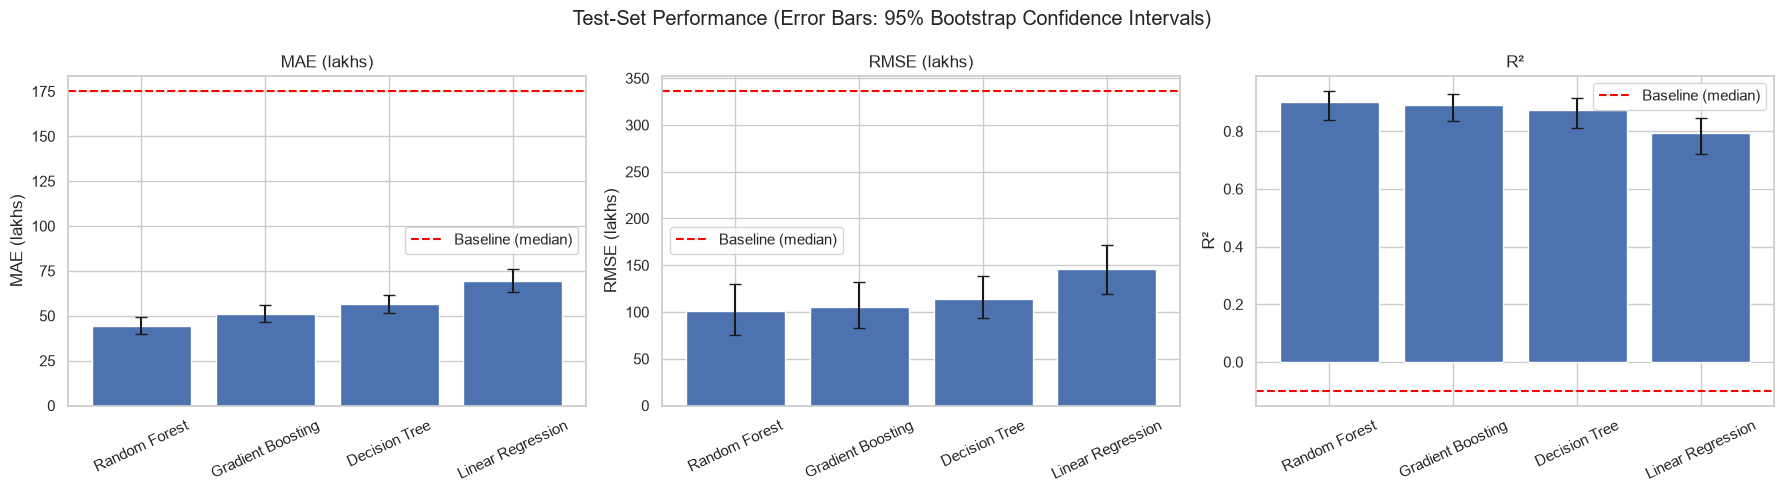

Chart saved to: D:\real-estate-price-prediction\reports\figures\12_test_metrics.png


In [49]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Remove the baseline from the model bars
show = results.drop(index="Baseline (median)")
base = results.loc["Baseline (median)"]

# Metric names and their corresponding bootstrap keys
metric_mapping = {
    "MAE (lakhs)": "MAE",
    "RMSE (lakhs)": "RMSE",
    "R²": "R2",
}

# Create three side-by-side plots
fig, ax = plt.subplots(1, 3, figsize=(18, 5))

for a_, (metric, bootstrap_key) in zip(ax, metric_mapping.items()):

    # Sort models: lowest error first, highest R² first
    vals = show[metric].sort_values(
        ascending=(metric != "R²")
    )

    # Calculate 95% bootstrap confidence intervals
    lower_ci = np.array([
        np.nanpercentile(
            boots[name][bootstrap_key], 2.5
        )
        for name in vals.index
    ])

    upper_ci = np.array([
        np.nanpercentile(
            boots[name][bootstrap_key], 97.5
        )
        for name in vals.index
    ])

    # Error bars must be nonnegative
    lower_error = np.maximum(
        vals.values - lower_ci, 0
    )

    upper_error = np.maximum(
        upper_ci - vals.values, 0
    )

    errors = np.vstack([
        lower_error,
        upper_error
    ])

    # Draw model bars with bootstrap confidence intervals
    a_.bar(
        vals.index,
        vals.values,
        yerr=errors,
        capsize=4
    )

    # Draw the baseline performance
    a_.axhline(
        base[metric],
        color="red",
        linestyle="--",
        label="Baseline (median)"
    )

    a_.set_title(metric)
    a_.set_ylabel(metric)
    a_.tick_params(
        axis="x",
        rotation=25
    )
    a_.legend()

plt.suptitle(
    "Test-Set Performance "
    "(Error Bars: 95% Bootstrap Confidence Intervals)"
)

plt.tight_layout()

# Save the chart
chart_path = figures_dir / "12_test_metrics.png"

plt.savefig(
    chart_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("Chart saved to:", chart_path.resolve())

In [50]:
print("Chart exists:", chart_path.exists())

if chart_path.exists():
    print("File size:", round(chart_path.stat().st_size / 1024, 2), "KB")

Chart exists: True
File size: 128.79 KB


In [53]:
from pathlib import Path

print("Reports directory:", Path(reports_dir).resolve())
print("\nFiles inside reports:")

for path in sorted(Path(reports_dir).glob("*")):
    print(path.name)

NameError: name 'reports_dir' is not defined

In [54]:
from pathlib import Path

# Set your project directory
PROJECT_ROOT = Path.cwd().parent

# Set the reports directory
reports_dir = PROJECT_ROOT / "reports"

print("Project root:", PROJECT_ROOT.resolve())
print("Reports directory:", reports_dir.resolve())
print("Reports directory exists:", reports_dir.exists())

print("\nFiles inside reports:")

if reports_dir.exists():
    for path in sorted(reports_dir.iterdir()):
        print(path.name)
else:
    print("Reports directory not found!")

Project root: D:\real-estate-price-prediction
Reports directory: D:\real-estate-price-prediction\reports
Reports directory exists: True

Files inside reports:
bootstrap_confidence_intervals.csv
bootstrap_model_comparison.csv
cv_baseline.csv
cv_comparison.csv
data_dictionary.md
distance_correlations.csv
figures
largest_prediction_errors.csv
locality_map.html
location_price_correlations.csv
model_evaluation_report.md
model_improvement_vs_linear.csv
model_tuning_results.csv
performance_by_price_range.csv
prediction_error_analysis.csv
preprocessing_log.csv
price_map.html
test_evaluation_results.csv
test_metrics.csv
tuned_model_comparison.csv


In [55]:
# Search the entire project for relevant CSV files
matches = []

for path in PROJECT_ROOT.rglob("*.csv"):
    if ".git" not in path.parts and "venv" not in path.parts:
        if any(
            word in path.name.lower()
            for word in ["cv", "comparison", "model"]
        ):
            matches.append(path)

print("Matching CSV files:")

if matches:
    for path in matches:
        print(path)
else:
    print("No matching CSV files found.")

Matching CSV files:
d:\real-estate-price-prediction\reports\bootstrap_model_comparison.csv
d:\real-estate-price-prediction\reports\cv_baseline.csv
d:\real-estate-price-prediction\reports\cv_comparison.csv
d:\real-estate-price-prediction\reports\model_improvement_vs_linear.csv
d:\real-estate-price-prediction\reports\model_tuning_results.csv
d:\real-estate-price-prediction\reports\tuned_model_comparison.csv
d:\real-estate-price-prediction\notebooks\reports\baseline_cv_results_v2.csv
d:\real-estate-price-prediction\notebooks\reports\baseline_cv_results_v2_full_precision.csv
d:\real-estate-price-prediction\notebooks\reports\cv_results_decision_tree_v2.csv
d:\real-estate-price-prediction\notebooks\reports\cv_results_gradient_boosting_10_iter_v2.csv
d:\real-estate-price-prediction\notebooks\reports\cv_results_gradient_boosting_v2.csv
d:\real-estate-price-prediction\notebooks\reports\cv_results_random_forest_v2.csv
d:\real-estate-price-prediction\notebooks\reports\cv_results_ridge_v2.csv
d:\r

In [56]:
import pandas as pd
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent
reports_dir = PROJECT_ROOT / "reports"

cv_path = reports_dir / "cv_comparison.csv"

cv_table = pd.read_csv(cv_path, index_col=0)

print("CV file loaded:", cv_path.exists())
print("\nColumns:")
print(cv_table.columns.tolist())

print("\nCV comparison results:")
display(cv_table)

CV file loaded: True

Columns:
['cv_r2', 'cv_r2_std', 'train_r2', 'cv_rmse_log', 'cv_mae_log', 'overfit_gap']

CV comparison results:


,cv_r2,cv_r2_std,train_r2,cv_rmse_log,cv_mae_log,overfit_gap
model,,,,,,
Random Forest,0.9106,0.0086,0.9815,0.1828,0.1224,0.0709
Gradient Boosting,0.9072,0.0103,0.9385,0.1862,0.1327,0.0314
Linear Regression,0.8531,0.0103,0.8615,0.2345,0.1723,0.0084
Decision Tree,0.8493,0.0148,0.9511,0.2374,0.1568,0.1018


In [57]:
print("Model names in CV report:")
print(cv_table.index.tolist())

print("\nModel names in test results:")
print(results.index.tolist())

print("\nModel names in predictions:")
print(list(preds.keys()))

Model names in CV report:
['Random Forest', 'Gradient Boosting', 'Linear Regression', 'Decision Tree']

Model names in test results:
['Random Forest', 'Gradient Boosting', 'Decision Tree', 'Linear Regression', 'Baseline (median)']

Model names in predictions:
['Linear Regression', 'Decision Tree', 'Random Forest', 'Gradient Boosting', 'Baseline (median)']


In [58]:
import numpy as np
from sklearn.metrics import mean_squared_error

# Models available in both the CV report and predictions
required_models = [
    "Linear Regression",
    "Decision Tree",
    "Random Forest",
    "Gradient Boosting"
]

available_models = [
    name for name in required_models
    if name in cv_table.index and name in preds
]

print("Models included:", available_models)

if not available_models:
    raise ValueError(
        "No matching model names. Check the output from Step 2."
    )

# Actual test prices in lakhs
y_test_array = np.asarray(y_test, dtype=float).reshape(-1)

# Calculate test RMSE using log-transformed prices
rmse_log_test = {}

for name in available_models:

    prediction = np.asarray(
        preds[name], dtype=float
    ).reshape(-1)

    if len(prediction) != len(y_test_array):
        raise ValueError(
            f"Prediction length mismatch for {name}"
        )

    # Prevent negative prices before applying log1p
    prediction = np.clip(prediction, 0, None)

    rmse_log_test[name] = np.sqrt(
        mean_squared_error(
            np.log1p(y_test_array),
            np.log1p(prediction)
        )
    )

# Combine CV and test RMSE
cv_rmse = cv_table.loc[
    available_models, "cv_rmse_log"
].astype(float)

test_rmse = pd.Series(
    rmse_log_test,
    name="test_rmse_log"
)

chk = pd.concat(
    [
        cv_rmse.rename("cv_rmse_log"),
        test_rmse
    ],
    axis=1
)

# Calculate the gap
chk["gap"] = (
    chk["test_rmse_log"] - chk["cv_rmse_log"]
)

display(chk.round(4))

Models included: ['Linear Regression', 'Decision Tree', 'Random Forest', 'Gradient Boosting']


,cv_rmse_log,test_rmse_log,gap
Linear Regression,0.2345,0.2355,0.0010
Decision Tree,0.2374,0.2364,-0.0010
Random Forest,0.1828,0.1801,-0.0027
Gradient Boosting,0.1862,0.1917,0.0055


In [59]:
cv_test_path = reports_dir / "cv_vs_test_comparison.csv"

chk.to_csv(cv_test_path)

print("Saved successfully:", cv_test_path.exists())
print("Location:", cv_test_path.resolve())

Saved successfully: True
Location: D:\real-estate-price-prediction\reports\cv_vs_test_comparison.csv


In [1]:
from pathlib import Path
import os

# Move to project root if currently inside notebooks/
if Path.cwd().name == "notebooks":
    os.chdir("..")

PROJECT_ROOT = Path.cwd()

print("Project root:", PROJECT_ROOT)
print("Current directory:", Path.cwd())

Project root: d:\real-estate-price-prediction
Current directory: d:\real-estate-price-prediction


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import joblib
import json

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

from scipy import stats

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
df = pd.read_csv("data/processed/model_data.csv")

print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())
print("\nFirst five rows:")
display(df.head())

Dataset shape: (7457, 19)

Columns:
['prop_id', 'bedroom_num', 'bathroom_num', 'balcony_num', 'floor_num', 'total_floor', 'total_landmark_count', 'area_sqft', 'property_type', 'owntype', 'furnish', 'facing', 'age', 'locality_grouped', 'latitude', 'longitude', 'price_lakhs', 'log_price', 'split']

First five rows:


,prop_id,bedroom_num,bathroom_num,balcony_num,floor_num,total_floor,total_landmark_count,area_sqft,property_type,owntype,furnish,facing,age,locality_grouped,latitude,longitude,price_lakhs,log_price,split
0,O71585872,4.0,4,4.0,14.0,26.0,10.0,3434.0,Residential Apartment,1,4,1,2,Sector 84 Gurgaon,28.406534,76.962792,263.0,5.575949,test
1,T71585466,4.0,4,3.0,7.0,29.0,9.0,2870.0,Residential Apartment,1,4,1,1,Sector 81 Gurgaon,28.388907,76.951328,360.0,5.888878,train
2,I71493958,3.0,3,3.0,14.0,28.0,8.0,2802.0,Residential Apartment,1,4,0,1,Sector 112 Gurgaon,28.518677,77.015115,385.0,5.955837,train
3,X71361930,3.0,4,4.0,4.0,27.0,14.0,2290.0,Residential Apartment,1,4,2,1,Sector 104 Gurgaon,28.478440,76.986110,195.0,5.278115,train
4,N71483500,2.0,2,3.0,12.0,30.0,13.0,1400.0,Residential Apartment,1,2,3,6,Sector 74 Gurgaon,28.416400,77.012620,162.0,5.093750,train


In [4]:
with open("models/feature_config.json", "r") as f:
    feature_config = json.load(f)

NUM = feature_config["numeric_features"]
CAT = feature_config["categorical_features"]

FEATURES = NUM + CAT

TARGET = feature_config["target"]
ORIGINAL_TARGET = feature_config["original_target"]
SPLIT_COL = feature_config["split_column"]

print("Numeric features:", NUM)
print("\nCategorical features:", CAT)

print("\nTotal numeric features:", len(NUM))
print("Total categorical features:", len(CAT))
print("Total features:", len(FEATURES))

print("\nTarget:", TARGET)
print("Original target:", ORIGINAL_TARGET)
print("Split column:", SPLIT_COL)

Numeric features: ['bedroom_num', 'bathroom_num', 'balcony_num', 'floor_num', 'total_floor', 'total_landmark_count', 'area_sqft', 'latitude', 'longitude']

Categorical features: ['property_type', 'owntype', 'furnish', 'facing', 'age', 'locality_grouped']

Total numeric features: 9
Total categorical features: 6
Total features: 15

Target: log_price
Original target: price_lakhs
Split column: split


In [5]:
# Select only test records
test_df = df[df[SPLIT_COL] == "test"].copy()

# Select input features
X_test = test_df[FEATURES].copy()

# Actual property prices in lakhs
y_test = test_df[ORIGINAL_TARGET].copy()

# Actual log-transformed prices
y_test_log = test_df[TARGET].copy()

print("Test dataset shape:", X_test.shape)
print("Actual prices shape:", y_test.shape)

print("\nNumber of test records:", len(test_df))
print("Number of features:", len(FEATURES))

print("\nMissing values in actual prices:", y_test.isna().sum())

Test dataset shape: (1492, 15)
Actual prices shape: (1492,)

Number of test records: 1492
Number of features: 15

Missing values in actual prices: 0


In [6]:
model_paths = {
    "Linear Regression": "models/linear_regression_tuned.joblib",
    "Decision Tree": "models/decision_tree_tuned.joblib",
    "Random Forest": "models/random_forest_tuned.joblib",
    "Gradient Boosting": "models/gradient_boosting_tuned.joblib"
}

files = list(model_paths.keys())

models = {}

for name, path in model_paths.items():
    models[name] = joblib.load(path)
    print(f"{name} loaded successfully!")

Linear Regression loaded successfully!
Decision Tree loaded successfully!
Random Forest loaded successfully!
Gradient Boosting loaded successfully!


In [7]:
preds = {}

for name, model in models.items():

    # Generate predictions in log-price format
    pred_log = model.predict(X_test)

    # Convert predictions into actual prices (lakhs)
    pred_price = np.expm1(pred_log)

    # Prevent negative predicted prices
    pred_price = np.maximum(pred_price, 0)

    preds[name] = pred_price

    print(f"{name}: Predictions generated successfully!")

Linear Regression: Predictions generated successfully!
Decision Tree: Predictions generated successfully!
Random Forest: Predictions generated successfully!
Gradient Boosting: Predictions generated successfully!


In [8]:
from pathlib import Path

figures_dir = Path("reports/figures")
figures_dir.mkdir(parents=True, exist_ok=True)

print("Figures directory ready:", figures_dir)

Figures directory ready: reports\figures


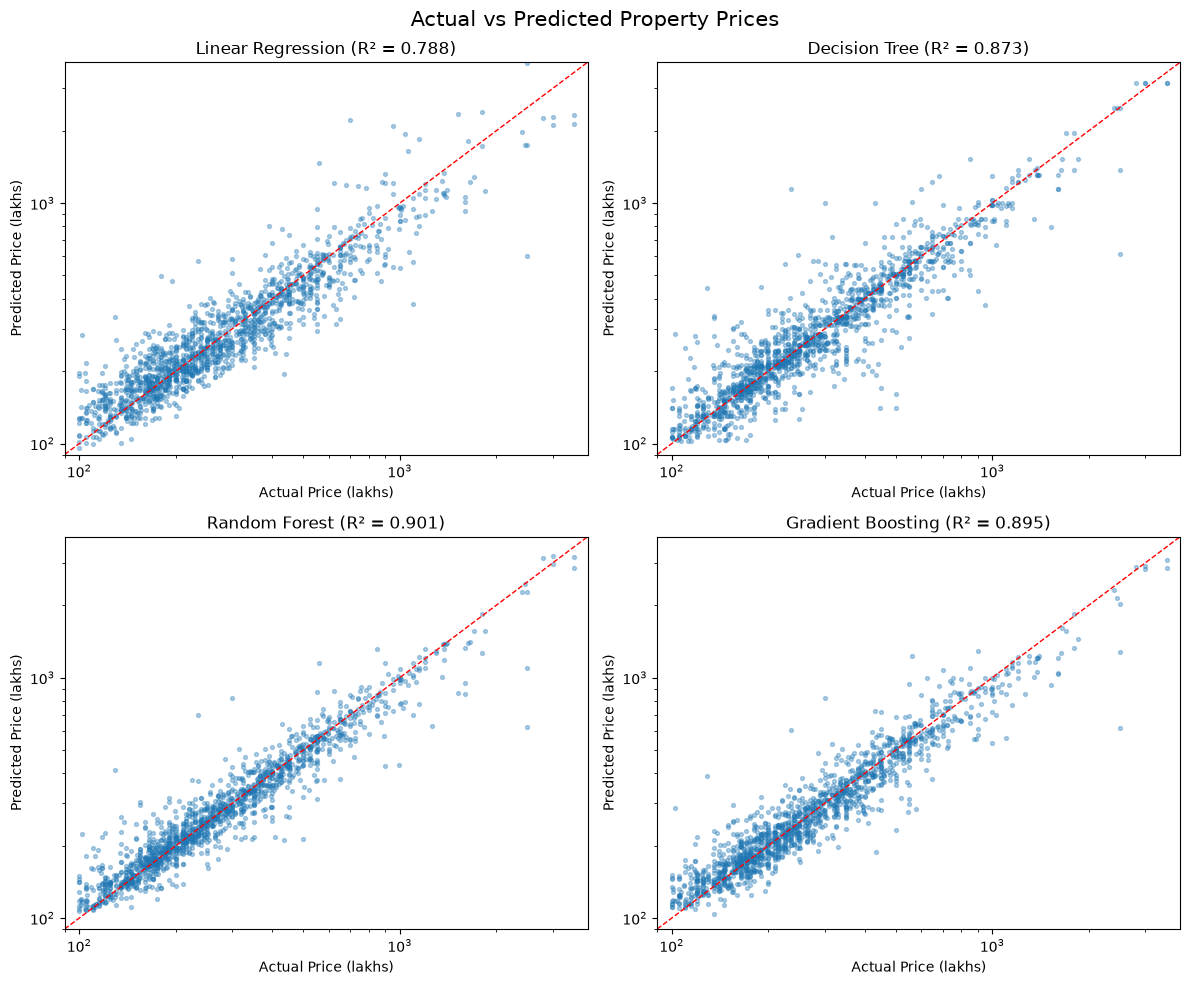

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

# Set common axis limits
lim = [
    max(1, y_test.min() * 0.9),
    y_test.max() * 1.1
]

# Generate one plot for each model
for ax, name in zip(axes.ravel(), files):

    p = preds[name]

    # Actual vs predicted scatter plot
    ax.scatter(
        y_test,
        p,
        s=8,
        alpha=0.35
    )

    # Perfect prediction reference line
    ax.plot(lim, lim, "r--", lw=1)

    # Configure axes
    ax.set(
        xscale="log",
        yscale="log",
        xlim=lim,
        ylim=lim,
        xlabel="Actual Price (lakhs)",
        ylabel="Predicted Price (lakhs)",
        title=f"{name} (R² = {r2_score(y_test, p):.3f})"
    )

plt.suptitle(
    "Actual vs Predicted Property Prices",
    fontsize=15
)

plt.tight_layout()

# Save the graph
plt.savefig(
    figures_dir / "13_actual_vs_predicted.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

In [10]:
plot_path = figures_dir / "13_actual_vs_predicted.png"

print("Graph saved:", plot_path.exists())
print("File location:", plot_path.resolve())

Graph saved: True
File location: D:\real-estate-price-prediction\reports\figures\13_actual_vs_predicted.png


In [11]:
lead = "Gradient Boosting"

p = preds[lead]

print("Leading model:", lead)
print("Number of predictions:", len(p))

Leading model: Gradient Boosting
Number of predictions: 1492


In [12]:
# Difference between predicted and actual prices
res = p - y_test

# Percentage error
pct = (res / y_test) * 100

# Log-transformed residuals
logres = np.log1p(p) - np.log1p(y_test)

print("Mean residual:", np.mean(res))
print("Median residual:", np.median(res))
print("Mean absolute residual:", np.mean(np.abs(res)))

Mean residual: -9.430824848949655
Median residual: 0.7014574260722668
Mean absolute residual: 49.79493401192267


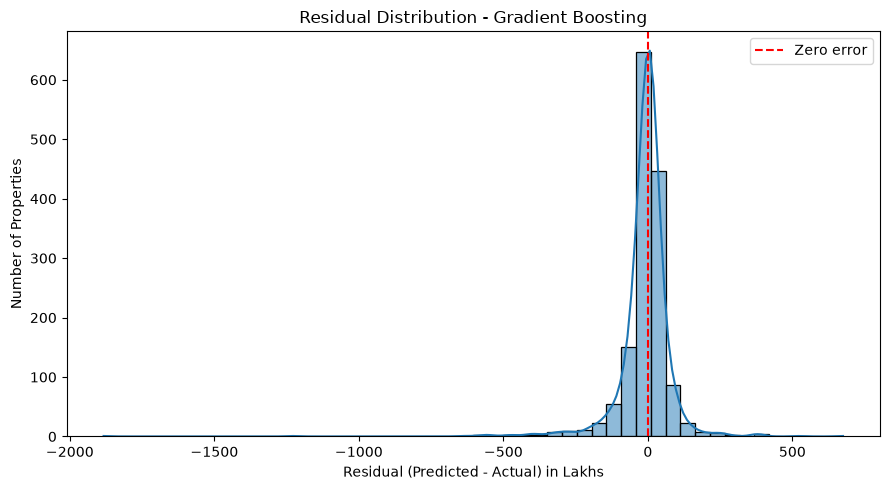

In [13]:
plt.figure(figsize=(9, 5))

sns.histplot(res, bins=50, kde=True)

plt.axvline(0, color="red", linestyle="--", label="Zero error")

plt.title(f"Residual Distribution - {lead}")
plt.xlabel("Residual (Predicted - Actual) in Lakhs")
plt.ylabel("Number of Properties")
plt.legend()

plt.tight_layout()

plt.savefig(
    figures_dir / "14_residual_distribution.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

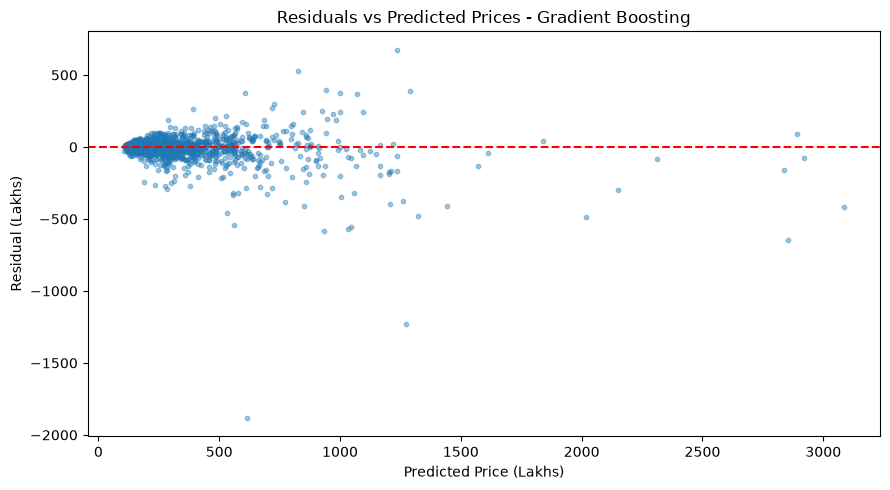

In [14]:
plt.figure(figsize=(9, 5))

plt.scatter(p, res, s=10, alpha=0.4)

plt.axhline(0, color="red", linestyle="--")

plt.title(f"Residuals vs Predicted Prices - {lead}")
plt.xlabel("Predicted Price (Lakhs)")
plt.ylabel("Residual (Lakhs)")

plt.tight_layout()

plt.savefig(
    figures_dir / "15_residuals_vs_predicted.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

In [15]:
print("Residual Analysis -", lead)
print("-" * 40)

print(f"Mean Error: {np.mean(res):.2f} lakhs")
print(f"Median Error: {np.median(res):.2f} lakhs")
print(f"Standard Deviation: {np.std(res):.2f} lakhs")

print(f"Minimum Error: {np.min(res):.2f} lakhs")
print(f"Maximum Error: {np.max(res):.2f} lakhs")

print(f"Overpredictions: {(res > 0).sum()}")
print(f"Underpredictions: {(res < 0).sum()}")
print(f"Exact Predictions: {(res == 0).sum()}")

Residual Analysis - Gradient Boosting
----------------------------------------
Mean Error: -9.43 lakhs
Median Error: 0.70 lakhs
Standard Deviation: 103.45 lakhs
Minimum Error: -1883.10 lakhs
Maximum Error: 675.24 lakhs
Overpredictions: 760
Underpredictions: 732
Exact Predictions: 0


In [16]:
error_df = pd.DataFrame({
    "Actual Price": y_test,
    "Predicted Price": p,
    "Residual": res,
    "Absolute Error": np.abs(res),
    "Percentage Error": pct
}, index=y_test.index)

error_df = error_df.sort_values(
    by="Absolute Error",
    ascending=False
)

error_df.head(10)

,Actual Price,Predicted Price,Residual,Absolute Error,Percentage Error
5095,2500.0,616.902982,-1883.097018,1883.097018,-75.323881
625,2500.0,1273.773424,-1226.226576,1226.226576,-49.049063
5803,560.0,1235.238074,675.238074,675.238074,120.578227
2858,3500.0,2854.593760,-645.406240,645.406240,-18.440178
2882,1520.0,933.431114,-586.568886,586.568886,-38.590058
496,1600.0,1031.263126,-568.736874,568.736874,-35.546055
6314,1600.0,1047.066261,-552.933739,552.933739,-34.558359
957,1100.0,561.132205,-538.867795,538.867795,-48.987981
2614,300.0,824.695797,524.695797,524.695797,174.898599
1790,2500.0,2015.959751,-484.040249,484.040249,-19.361610


In [17]:
top_10_indices = error_df.head(10).index

property_details = test_df.loc[
    top_10_indices,
    FEATURES + [ORIGINAL_TARGET]
].copy()

property_details = property_details.join(
    error_df[["Predicted Price", "Absolute Error", "Percentage Error"]]
)

property_details

,bedroom_num,bathroom_num,balcony_num,floor_num,total_floor,total_landmark_count,area_sqft,latitude,longitude,property_type,owntype,furnish,facing,age,locality_grouped,price_lakhs,Predicted Price,Absolute Error,Percentage Error
5095,4.0,5,4.0,4.0,4.0,46.0,4500.0,28.475491,77.103210,Independent/Builder Floor,1,4,5,6,DLF Phase 1,2500.0,616.902982,1883.097018,-75.323881
625,4.0,4,4.0,NaN,2.0,48.0,9000.0,28.433339,77.105472,Independent House/Villa,1,2,1,2,Sector 54 Gurgaon,2500.0,1273.773424,1226.226576,-49.049063
5803,5.0,5,2.0,NaN,2.0,44.0,5500.0,28.488040,77.087650,Independent House/Villa,1,4,8,1,Sushant Lok Phase 1,560.0,1235.238074,675.238074,120.578227
2858,4.0,4,3.0,12.0,24.0,15.0,6400.0,28.453820,77.099560,Residential Apartment,1,0,1,2,Sector 42 Gurgaon,3500.0,2854.593760,645.406240,-18.440178
2882,5.0,6,4.0,2.0,3.0,8.0,9000.0,28.475081,77.108819,Independent/Builder Floor,1,4,3,6,DLF Phase 1,1520.0,933.431114,586.568886,-38.590058
496,4.0,4,4.0,NaN,2.0,9.0,4250.0,28.484342,77.088299,Independent House/Villa,1,1,5,2,DLF Phase 2,1600.0,1031.263126,568.736874,-35.546055
6314,4.0,5,3.0,NaN,2.0,3.0,3600.0,28.489563,77.087681,Independent House/Villa,1,4,5,2,DLF Phase 2,1600.0,1047.066261,552.933739,-34.558359
957,3.0,3,4.0,NaN,1.0,45.0,3240.0,28.419344,77.059423,Independent House/Villa,1,4,3,3,Other,1100.0,561.132205,538.867795,-48.987981
2614,3.0,3,3.0,NaN,1.0,49.0,3240.0,28.458338,77.066520,Independent House/Villa,1,2,5,2,South City 1,300.0,824.695797,524.695797,174.898599
1790,4.0,6,4.0,8.0,17.0,12.0,5600.0,28.459190,77.102240,Residential Apartment,1,0,5,3,Sector 42 Gurgaon,2500.0,2015.959751,484.040249,-19.361610


In [18]:
suspicious = property_details[
    property_details["area_sqft"] < 300
]

print("Properties with area below 300 sq. ft.:")
display(
    suspicious[
        [
            "bedroom_num",
            "bathroom_num",
            "area_sqft",
            "property_type",
            "locality_grouped",
            "price_lakhs",
            "Predicted Price"
        ]
    ]
)

Properties with area below 300 sq. ft.:


,bedroom_num,bathroom_num,area_sqft,property_type,locality_grouped,price_lakhs,Predicted Price


In [19]:
print("Area values of top 10 error properties:")

print(
    property_details[
        ["area_sqft", "price_lakhs", "Predicted Price"]
    ].to_string()
)

Area values of top 10 error properties:
      area_sqft  price_lakhs  Predicted Price
5095     4500.0       2500.0       616.902982
625      9000.0       2500.0      1273.773424
5803     5500.0        560.0      1235.238074
2858     6400.0       3500.0      2854.593760
2882     9000.0       1520.0       933.431114
496      4250.0       1600.0      1031.263126
6314     3600.0       1600.0      1047.066261
957      3240.0       1100.0       561.132205
2614     3240.0        300.0       824.695797
1790     5600.0       2500.0      2015.959751


In [20]:
print("Error percentage summary:")
print("-" * 40)

print(f"Mean absolute percentage error: {np.mean(np.abs(pct)):.2f}%")
print(f"Median absolute percentage error: {np.median(np.abs(pct)):.2f}%")

print("\nProperties with more than 50% prediction error:")

high_error = error_df[
    error_df["Percentage Error"].abs() > 50
]

print("Number of properties:", len(high_error))
print("Percentage of test dataset:",
      len(high_error) / len(error_df) * 100)

Error percentage summary:
----------------------------------------
Mean absolute percentage error: 13.82%
Median absolute percentage error: 10.15%

Properties with more than 50% prediction error:
Number of properties: 35
Percentage of test dataset: 2.3458445040214477


In [21]:
error_df.to_csv(
    "reports/gradient_boosting_error_analysis.csv",
    index=True
)

print("Error analysis saved successfully!")

Error analysis saved successfully!


In [22]:
expected_files = [
    "13_actual_vs_predicted.png",
    "14_residual_distribution.png",
    "15_residuals_vs_predicted.png"
]

print("PART E - FILE VERIFICATION")
print("-" * 40)

for filename in expected_files:
    path = figures_dir / filename
    print(f"{filename}: {'FOUND' if path.exists() else 'MISSING'}")

csv_path = Path("reports/gradient_boosting_error_analysis.csv")
print(
    f"gradient_boosting_error_analysis.csv: "
    f"{'FOUND' if csv_path.exists() else 'MISSING'}"
)

PART E - FILE VERIFICATION
----------------------------------------
13_actual_vs_predicted.png: FOUND
14_residual_distribution.png: FOUND
15_residuals_vs_predicted.png: FOUND
gradient_boosting_error_analysis.csv: FOUND


In [23]:
print("Is cfg available?", "cfg" in globals())

print("\nFeature configuration:")
print(feature_config)

if "cfg" in globals():
    print("\nFeature groups:")
    print(cfg.get("groups", "No groups found"))

Is cfg available? False

Feature configuration:
{'numeric_features': ['bedroom_num', 'bathroom_num', 'balcony_num', 'floor_num', 'total_floor', 'total_landmark_count', 'area_sqft', 'latitude', 'longitude'], 'categorical_features': ['property_type', 'owntype', 'furnish', 'facing', 'age', 'locality_grouped'], 'target': 'log_price', 'original_target': 'price_lakhs', 'identifier': 'prop_id', 'split_column': 'split', 'description': 'Core property features for Gurgaon real-estate price prediction. The target is log1p(price_lakhs).'}


In [24]:
print("MODEL DATA COLUMNS:")
print(df.columns.tolist())

print("\nLOCATION FEATURES FILE:")
location_path = Path("data/processed/location_features.csv")

if location_path.exists():
    location_df = pd.read_csv(location_path)
    print("Shape:", location_df.shape)
    print("Columns:")
    print(location_df.columns.tolist())
else:
    print("location_features.csv not found at:", location_path)

MODEL DATA COLUMNS:
['prop_id', 'bedroom_num', 'bathroom_num', 'balcony_num', 'floor_num', 'total_floor', 'total_landmark_count', 'area_sqft', 'property_type', 'owntype', 'furnish', 'facing', 'age', 'locality_grouped', 'latitude', 'longitude', 'price_lakhs', 'log_price', 'split']

LOCATION FEATURES FILE:
Shape: (7457, 16)
Columns:
['prop_id', 'dist_railway_km', 'dist_bus_km', 'dist_school_km', 'dist_hospital_km', 'dist_mall_km', 'dist_highway_km', 'dist_mainroad_km', 'n_school_1km', 'n_school_2km', 'n_hospital_1km', 'n_hospital_2km', 'n_bus_1km', 'n_bus_2km', 'n_mall_1km', 'n_mall_2km']


In [25]:
# Load location features
location_df = pd.read_csv("data/processed/location_features.csv")

# Keep the original model data unchanged
df_f = df.copy()

# Merge amenity features using property ID
df_f = df_f.merge(
    location_df,
    on="prop_id",
    how="left",
    validate="one_to_one"
)

print("Original dataset shape:", df.shape)
print("Merged dataset shape:", df_f.shape)

# Check missing amenity values
amenity_cols = [
    c for c in location_df.columns
    if c != "prop_id"
]

print("\nMissing amenity values:")
print(df_f[amenity_cols].isnull().sum())

print("\nDuplicate property IDs:", df_f["prop_id"].duplicated().sum())

Original dataset shape: (7457, 19)
Merged dataset shape: (7457, 34)

Missing amenity values:
dist_railway_km     0
dist_bus_km         0
dist_school_km      0
dist_hospital_km    0
dist_mall_km        0
dist_highway_km     0
dist_mainroad_km    0
n_school_1km        0
n_school_2km        0
n_hospital_1km      0
n_hospital_2km      0
n_bus_1km           0
n_bus_2km           0
n_mall_1km          0
n_mall_2km          0
dtype: int64

Duplicate property IDs: 0


In [26]:
# Property numeric features
prop_num = [
    "bedroom_num",
    "bathroom_num",
    "balcony_num",
    "floor_num",
    "total_floor",
    "area_sqft"
]

# Property categorical features
prop_cat = [
    "property_type",
    "owntype",
    "furnish",
    "facing",
    "age"
]

# Location features
loc_num = [
    "latitude",
    "longitude",
    "total_landmark_count"
]

loc_cat = ["locality_grouped"]

# Amenity numeric features
am_num = [
    "dist_railway_km",
    "dist_bus_km",
    "dist_school_km",
    "dist_hospital_km",
    "dist_mall_km",
    "dist_highway_km",
    "dist_mainroad_km",
    "n_school_1km",
    "n_school_2km",
    "n_hospital_1km",
    "n_hospital_2km",
    "n_bus_1km",
    "n_bus_2km",
    "n_mall_1km",
    "n_mall_2km"
]

am_cat = []

print("Property numeric:", len(prop_num))
print("Property categorical:", len(prop_cat))
print("Location numeric:", len(loc_num))
print("Location categorical:", len(loc_cat))
print("Amenity numeric:", len(am_num))
print("Amenity categorical:", len(am_cat))

Property numeric: 6
Property categorical: 5
Location numeric: 3
Location categorical: 1
Amenity numeric: 15
Amenity categorical: 0


In [27]:
sets = {
    "A. Property only":
        (prop_num, prop_cat),

    "B. A + location (no amenities)":
        (prop_num + loc_num, prop_cat + loc_cat),

    "C. B + amenities (full model)":
        (prop_num + loc_num + am_num,
         prop_cat + loc_cat + am_cat),

    "D. A + amenities (no locality/coords)":
        (prop_num + am_num, prop_cat + am_cat)
}

# Verify Set C against the merged dataset
num_c, cat_c = sets["C. B + amenities (full model)"]

print("Features in Set C but missing from dataset:")
print(set(num_c + cat_c) - set(df_f.columns))

print("\nDataset features missing from Set C:")
print(set(
    prop_num + prop_cat + loc_num + loc_cat + am_num + am_cat
) - set(num_c + cat_c))

print("\nFeature counts:")
for label, (num, cat) in sets.items():
    print(f"{label}: {len(num) + len(cat)} features")

Features in Set C but missing from dataset:
set()

Dataset features missing from Set C:
set()

Feature counts:
A. Property only: 11 features
B. A + location (no amenities): 15 features
C. B + amenities (full model): 30 features
D. A + amenities (no locality/coords): 26 features


In [28]:
sets = {
    "A. Property only":
        (prop_num, prop_cat),

    "B. A + location (no amenities)":
        (prop_num + loc_num, prop_cat + loc_cat),

    "C. B + amenities (full model)":
        (prop_num + loc_num + am_num,
         prop_cat + loc_cat + am_cat),

    "D. A + amenities (no locality/coords)":
        (prop_num + am_num, prop_cat + am_cat)
}

# Verify Set C against the merged dataset
num_c, cat_c = sets["C. B + amenities (full model)"]

print("Features in Set C but missing from dataset:")
print(set(num_c + cat_c) - set(df_f.columns))

print("\nDataset features missing from Set C:")
print(set(
    prop_num + prop_cat + loc_num + loc_cat + am_num + am_cat
) - set(num_c + cat_c))

print("\nFeature counts:")
for label, (num, cat) in sets.items():
    print(f"{label}: {len(num) + len(cat)} features")

Features in Set C but missing from dataset:
set()

Dataset features missing from Set C:
set()

Feature counts:
A. Property only: 11 features
B. A + location (no amenities): 15 features
C. B + amenities (full model): 30 features
D. A + amenities (no locality/coords): 26 features


In [29]:
# Separate training and testing data
train = df_f[df_f[SPLIT_COL] == "train"].copy()
test = df_f[df_f[SPLIT_COL] == "test"].copy()

# Target variables
y_train = train[TARGET].copy()
y_test = test[ORIGINAL_TARGET].copy()

print("Training shape:", train.shape)
print("Testing shape:", test.shape)

print("\nTraining target:", y_train.shape)
print("Testing target:", y_test.shape)

Training shape: (5965, 34)
Testing shape: (1492, 34)

Training target: (5965,)
Testing target: (1492,)


In [30]:
print("cv_table available:", "cv_table" in globals())
print("best_params available:", "best_params" in globals())

if "cv_table" in globals():
    print("\nCross-validation results:")
    display(cv_table)

cv_table available: False
best_params available: False


In [31]:
with open("models/best_model_params.json", "r") as f:
    best_params = json.load(f)

print("Saved model parameters:")
print(json.dumps(best_params, indent=4))

Saved model parameters:
{
    "Linear Regression": {
        "model__fit_intercept": true,
        "model__positive": false
    },
    "Decision Tree": {
        "model__min_samples_split": 20,
        "model__min_samples_leaf": 1,
        "model__max_features": null,
        "model__max_depth": 20
    },
    "Random Forest": {
        "model__n_estimators": 400,
        "model__min_samples_split": 5,
        "model__min_samples_leaf": 1,
        "model__max_features": 0.7,
        "model__max_depth": null
    },
    "Gradient Boosting": {
        "model__subsample": 0.9,
        "model__n_estimators": 400,
        "model__min_samples_split": 5,
        "model__min_samples_leaf": 2,
        "model__max_depth": 4,
        "model__learning_rate": 0.05
    }
}


In [32]:
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.ensemble import GradientBoostingRegressor

from sklearn.model_selection import KFold, cross_validate
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

In [33]:
best_name = "Gradient Boosting"

print("Selected model:", best_name)
print("Parameters:", best_params[best_name])

Selected model: Gradient Boosting
Parameters: {'model__subsample': 0.9, 'model__n_estimators': 400, 'model__min_samples_split': 5, 'model__min_samples_leaf': 2, 'model__max_depth': 4, 'model__learning_rate': 0.05}


In [34]:
def make_pre(num, cat, scale=False):

    # Numeric preprocessing
    ns = [
        ("imp", SimpleImputer(strategy="median"))
    ]

    if scale:
        ns.append(("sc", StandardScaler()))

    # Categorical preprocessing
    cs = Pipeline([
        ("imp", SimpleImputer(
            strategy="constant",
            fill_value="Unknown"
        )),
        ("oh", OneHotEncoder(
            handle_unknown="infrequent_if_exist",
            min_frequency=10,
            sparse_output=False
        ))
    ])

    return ColumnTransformer([
        ("num", Pipeline(ns), num),
        ("cat", cs, cat)
    ], remainder="drop")


print("Preprocessing function created successfully!")

Preprocessing function created successfully!


In [35]:
def build(name, num, cat, wrap=True):

    est = GradientBoostingRegressor(random_state=42)

    pipe = Pipeline([
        ("pre", make_pre(num, cat, scale=False)),
        ("model", est)
    ])

    # Apply the saved tuned parameters
    pipe.set_params(**best_params[name])

    if wrap:
        return TransformedTargetRegressor(
            regressor=pipe,
            func=np.log1p,
            inverse_func=np.expm1
        )

    return pipe


print("Model-building function created successfully!")

Model-building function created successfully!


In [36]:
cv5 = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

y_log = y_train

print("5-fold cross-validation prepared.")
print("Training records:", len(y_train))
print("Number of folds:", cv5.get_n_splits())

5-fold cross-validation prepared.
Training records: 5965
Number of folds: 5


In [37]:
rows = []

for label, (num, cat) in sets.items():

    print(f"Evaluating: {label}...")

    s = cross_validate(
        build(best_name, num, cat, wrap=False),
        train[num + cat],
        y_log,
        cv=cv5,
        scoring={
            "r2": "r2",
            "rmse": "neg_root_mean_squared_error"
        },
        n_jobs=-1
    )

    rows.append({
        "feature set": label,
        "n_features": len(num) + len(cat),
        "cv_r2": s["test_r2"].mean(),
        "cv_r2_std": s["test_r2"].std(),
        "cv_rmse_log": -s["test_rmse"].mean(),
        "cv_rmse_std": s["test_rmse"].std()
    })

print("\nCross-validation completed!")

Evaluating: A. Property only...
Evaluating: B. A + location (no amenities)...
Evaluating: C. B + amenities (full model)...
Evaluating: D. A + amenities (no locality/coords)...

Cross-validation completed!


In [38]:
abl_cv = pd.DataFrame(rows).set_index("feature set").round(4)

display(abl_cv)

,n_features,cv_r2,cv_r2_std,cv_rmse_log,cv_rmse_std
feature set,,,,,
A. Property only,11,0.8015,0.0183,0.2724,0.0073
B. A + location (no amenities),15,0.9081,0.0099,0.1852,0.0065
C. B + amenities (full model),30,0.9126,0.0091,0.1807,0.0061
D. A + amenities (no locality/coords),26,0.9054,0.0110,0.1879,0.0075


In [39]:
abl_preds = {}
rows = []

for label, (num, cat) in sets.items():

    print(f"Training: {label}...")

    m = build(best_name, num, cat, wrap=True)

    m.fit(train[num + cat], train[TARGET])

    abl_preds[label] = m.predict(test[num + cat])

print("\nAll four models trained successfully!")

Training: A. Property only...
Training: B. A + location (no amenities)...
Training: C. B + amenities (full model)...
Training: D. A + amenities (no locality/coords)...

All four models trained successfully!


In [40]:
def metrics(actual, predicted):
    ape = np.abs((actual - predicted) / actual) * 100

    return {
        "MAE (lakhs)": mean_absolute_error(actual, predicted),
        "RMSE (lakhs)": np.sqrt(mean_squared_error(actual, predicted)),
        "R²": r2_score(actual, predicted),
        "Median APE %": np.median(ape),
        "Within ±20%": np.mean(ape <= 20) * 100
    }


rows = []

for label, prediction in abl_preds.items():

    mt = metrics(y_test, prediction)

    rows.append({
        "feature set": label,
        **mt
    })

print("Test-set evaluation completed!")

Test-set evaluation completed!


In [41]:
abl_test = pd.DataFrame(rows).set_index("feature set").round(3)

display(abl_test)

,MAE (lakhs),RMSE (lakhs),R²,Median APE %,Within ±20%
feature set,,,,,
A. Property only,345.065,470.639,-1.157,97.815,0.0
B. A + location (no amenities),345.063,470.604,-1.156,97.799,0.0
C. B + amenities (full model),345.063,470.602,-1.156,97.808,0.0
D. A + amenities (no locality/coords),345.064,470.602,-1.156,97.805,0.0


In [42]:
abl_preds = {}

for label, (num, cat) in sets.items():

    print(f"Training: {label}...")

    m = build(best_name, num, cat, wrap=True)

    # Pass original prices, not log_price
    m.fit(
        train[num + cat],
        train[ORIGINAL_TARGET]
    )

    abl_preds[label] = m.predict(test[num + cat])

print("\nAll four models retrained successfully!")

Training: A. Property only...
Training: B. A + location (no amenities)...
Training: C. B + amenities (full model)...
Training: D. A + amenities (no locality/coords)...

All four models retrained successfully!


In [43]:
rows = []

for label, prediction in abl_preds.items():

    mt = metrics(y_test, prediction)

    rows.append({
        "feature set": label,
        **mt
    })

abl_test = pd.DataFrame(rows).set_index("feature set").round(3)

display(abl_test)

,MAE (lakhs),RMSE (lakhs),R²,Median APE %,Within ±20%
feature set,,,,,
A. Property only,78.117,156.535,0.761,16.553,58.914
B. A + location (no amenities),49.559,103.674,0.895,10.078,79.558
C. B + amenities (full model),47.682,103.462,0.896,9.200,80.697
D. A + amenities (no locality/coords),48.367,102.901,0.897,9.241,80.429


In [44]:
print("boot function available:", "boot" in globals())

boot function available: False


In [45]:
def boot(prediction, n_rep=1000, seed=42):
    rng = np.random.default_rng(seed)

    actual = np.asarray(y_test)
    predicted = np.asarray(prediction)

    results = {"MAE": [], "RMSE": []}

    for _ in range(n_rep):
        idx = rng.integers(0, len(actual), len(actual))

        error = actual[idx] - predicted[idx]

        results["MAE"].append(np.mean(np.abs(error)))
        results["RMSE"].append(np.sqrt(np.mean(error ** 2)))

    return {
        metric: np.asarray(values)
        for metric, values in results.items()
    }


print("Bootstrap function created successfully!")

Bootstrap function created successfully!


In [46]:
comparisons = [
    ("A vs B", "A. Property only", "B. A + location (no amenities)"),
    ("B vs C", "B. A + location (no amenities)", "C. B + amenities (full model)"),
    ("A vs D", "A. Property only", "D. A + amenities (no locality/coords)")
]

rows = []
rng = np.random.default_rng(42)

for question, a, b in comparisons:
    actual = np.asarray(y_test)
    pred_a = np.asarray(abl_preds[a])
    pred_b = np.asarray(abl_preds[b])

    mae_diff = []
    rmse_diff = []

    for _ in range(2000):
        idx = rng.integers(0, len(actual), len(actual))

        err_a = actual[idx] - pred_a[idx]
        err_b = actual[idx] - pred_b[idx]

        mae_diff.append(
            np.mean(np.abs(err_a)) - np.mean(np.abs(err_b))
        )
        rmse_diff.append(
            np.sqrt(np.mean(err_a ** 2)) -
            np.sqrt(np.mean(err_b ** 2))
        )

    for metric, differences in [
        ("MAE", np.asarray(mae_diff)),
        ("RMSE", np.asarray(rmse_diff))
    ]:
        lower, upper = np.percentile(differences, [2.5, 97.5])

        rows.append({
            "Comparison": question,
            "Metric": metric,
            "Error reduction (lakhs)": differences.mean(),
            "95% CI lower": lower,
            "95% CI upper": upper,
            "Significant improvement": lower > 0
        })

bootstrap_results = pd.DataFrame(rows).round(3)
display(bootstrap_results)

,Comparison,Metric,Error reduction (lakhs),95% CI lower,95% CI upper,Significant improvement
0,A vs B,MAE,28.522,23.928,33.347,True
1,A vs B,RMSE,52.666,31.557,76.792,True
2,B vs C,MAE,1.890,0.814,3.009,True
3,B vs C,RMSE,0.283,-3.044,3.532,False
4,A vs D,MAE,29.709,25.019,34.945,True
5,A vs D,RMSE,53.334,31.206,78.655,True


In [47]:
full_num, full_cat = sets["C. B + amenities (full model)"]

full_model = build(
    best_name,
    full_num,
    full_cat,
    wrap=True
)

full_model.fit(
    train[full_num + full_cat],
    train[ORIGINAL_TARGET]
)

print("Full model trained successfully.")
print("Number of input features:", len(full_num) + len(full_cat))

Full model trained successfully.
Number of input features: 30


In [48]:
from sklearn.inspection import permutation_importance

perm = permutation_importance(
    full_model,
    test[full_num + full_cat],
    test[ORIGINAL_TARGET],
    scoring="neg_root_mean_squared_error",
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

print("Permutation importance calculated successfully!")

Permutation importance calculated successfully!


In [49]:
importance_df = pd.DataFrame({
    "Feature": full_num + full_cat,
    "Importance": perm.importances_mean,
    "Std": perm.importances_std
})

importance_df = importance_df.sort_values(
    "Importance",
    ascending=False
).reset_index(drop=True)

display(importance_df.head(20).round(5))

,Feature,Importance,Std
0,area_sqft,176.27188,3.84732
1,locality_grouped,57.60835,1.02338
2,property_type,57.13220,5.91288
3,longitude,49.03887,4.41583
4,total_floor,21.24901,2.11353
5,n_bus_2km,15.92383,2.89409
6,bedroom_num,11.36646,2.09247
7,total_landmark_count,10.32923,4.35286
8,latitude,6.67622,1.76552
9,dist_railway_km,6.54208,1.19415


In [50]:
def get_group(feature):
    if feature in prop_num + prop_cat:
        return "Property"
    elif feature in loc_num + loc_cat:
        return "Location"
    else:
        return "Amenities"


importance_df["Group"] = importance_df["Feature"].apply(get_group)

group_importance = (
    importance_df.groupby("Group")["Importance"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

display(group_importance.round(4))

,Group,Importance
0,Property,273.8833
1,Location,123.6527
2,Amenities,37.5145


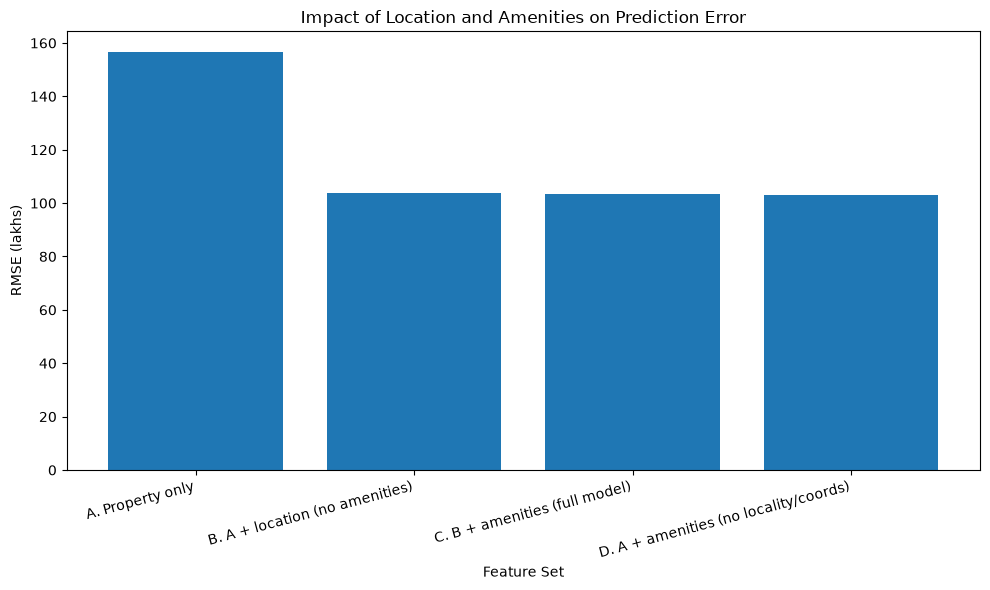

In [51]:
plt.figure(figsize=(10, 6))

plt.bar(
    abl_test.index,
    abl_test["RMSE (lakhs)"]
)

plt.ylabel("RMSE (lakhs)")
plt.xlabel("Feature Set")
plt.title("Impact of Location and Amenities on Prediction Error")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()

plt.show()

In [52]:
group_importance.to_csv(
    "reports/ablation_group_importance.csv",
    index=False
)

print("Group importance saved successfully!")

Group importance saved successfully!


In [53]:
abl_cv.to_csv("reports/ablation_cv.csv")

abl_test.to_csv("reports/ablation_test.csv")

print("Both ablation result tables saved successfully!")

Both ablation result tables saved successfully!


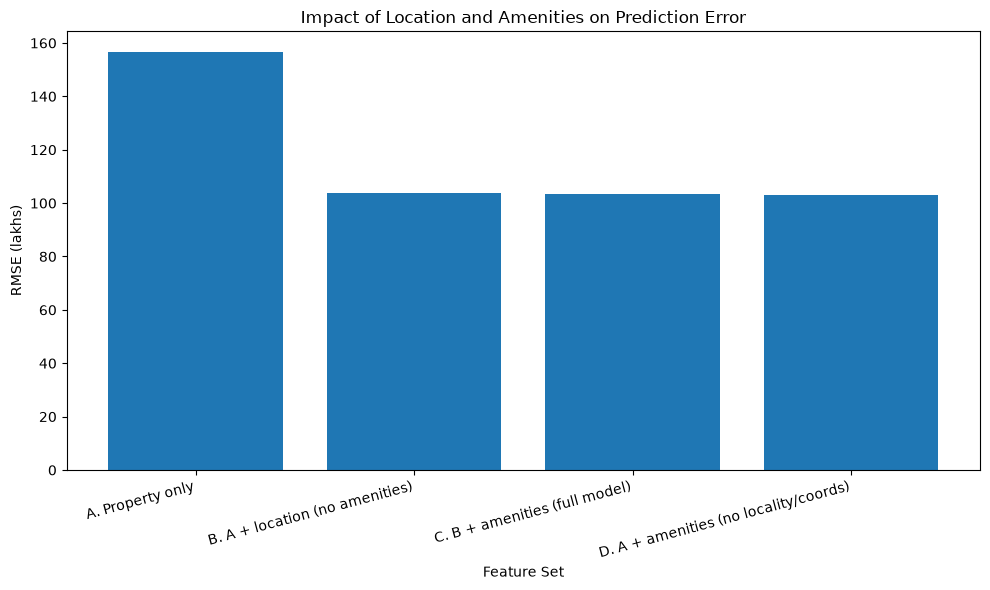

In [54]:
plt.figure(figsize=(10, 6))

plt.bar(
    abl_test.index,
    abl_test["RMSE (lakhs)"]
)

plt.ylabel("RMSE (lakhs)")
plt.xlabel("Feature Set")
plt.title("Impact of Location and Amenities on Prediction Error")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()

plt.savefig(
    figures_dir / "16_ablation.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [55]:
from pathlib import Path

files_to_check = [
    Path("reports/ablation_group_importance.csv"),
    Path("reports/ablation_cv.csv"),
    Path("reports/ablation_test.csv"),
    figures_dir / "16_ablation.png"
]

for file in files_to_check:
    print(f"{file}: {'FOUND' if file.exists() else 'MISSING'}")

reports\ablation_group_importance.csv: FOUND
reports\ablation_cv.csv: FOUND
reports\ablation_test.csv: FOUND
reports\figures\16_ablation.png: FOUND


In [56]:
print("Best model:", best_name)

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)
print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

print("\nTraining target sample:")
print(y_train.head())

print("\nModel type:")
print(type(models[best_name]))

Best model: Gradient Boosting


NameError: name 'X_train' is not defined

In [57]:
print([name for name in globals() if name in [
    "train", "test", "X_train", "X_test",
    "y_train", "y_test", "models",
    "abl_preds", "df_f", "feature_config"
]])

['feature_config', 'X_test', 'y_test', 'models', 'df_f', 'train', 'test', 'y_train', 'abl_preds']


In [58]:
print("Training target sample:")
print(y_train.head())

print("\nTest target sample:")
print(y_test.head())

print("\nTraining data shape:", train.shape)
print("Test data shape:", test.shape)

print("\nBest model:", best_name)
print("Available models:", list(models.keys()))

Training target sample:
1    5.888878
2    5.955837
3    5.278115
4    5.093750
5    5.398163
Name: log_price, dtype: float64

Test target sample:
0     263.0
8     350.0
14    130.0
17    635.0
19    225.0
Name: price_lakhs, dtype: float64

Training data shape: (5965, 34)
Test data shape: (1492, 34)

Best model: Gradient Boosting
Available models: ['Linear Regression', 'Decision Tree', 'Random Forest', 'Gradient Boosting']


In [59]:
best_model = models[best_name]

print("Model:", best_name)
print("Model type:", type(best_model))

print("\nExpected input features:")
print(feature_config["numeric_features"] + feature_config["categorical_features"])

Model: Gradient Boosting
Model type: <class 'sklearn.pipeline.Pipeline'>

Expected input features:
['bedroom_num', 'bathroom_num', 'balcony_num', 'floor_num', 'total_floor', 'total_landmark_count', 'area_sqft', 'latitude', 'longitude', 'property_type', 'owntype', 'furnish', 'facing', 'age', 'locality_grouped']


In [60]:
best_model = models[best_name]

print("Model:", best_name)
print("Model type:", type(best_model))

print("\nExpected input features:")
print(feature_config["numeric_features"] + feature_config["categorical_features"])

Model: Gradient Boosting
Model type: <class 'sklearn.pipeline.Pipeline'>

Expected input features:
['bedroom_num', 'bathroom_num', 'balcony_num', 'floor_num', 'total_floor', 'total_landmark_count', 'area_sqft', 'latitude', 'longitude', 'property_type', 'owntype', 'furnish', 'facing', 'age', 'locality_grouped']


In [61]:
feature_cols = (
    feature_config["numeric_features"]
    + feature_config["categorical_features"]
)

X_train = train[feature_cols].copy()
X_test = test[feature_cols].copy()

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("\nMissing values in X_train:", X_train.isnull().sum().sum())
print("Missing values in X_test:", X_test.isnull().sum().sum())

X_train shape: (5965, 15)
X_test shape: (1492, 15)

Missing values in X_train: 606
Missing values in X_test: 155


In [62]:
missing = X_train.isnull().sum()

print("Training columns with missing values:")
print(missing[missing > 0])

print("\nTest columns with missing values:")
print(X_test.isnull().sum()[X_test.isnull().sum() > 0])

Training columns with missing values:
balcony_num      3
floor_num      602
total_floor      1
dtype: int64

Test columns with missing values:
floor_num               152
total_floor               1
total_landmark_count      2
dtype: int64


In [63]:
print(best_model)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('numeric',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  ['bedroom_num',
                                                   'bathroom_num',
                                                   'balcony_num', 'floor_num',
                                                   'total_floor',
                                                   'total_landmark_count',
                                                   'area_sqft', 'latitude',
                                                   'longitude']),
                                                 ('categorical',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strat

In [64]:
sample_predictions = best_model.predict(X_test.iloc[:5])

print("Predictions (log-price):")
print(sample_predictions)

print("\nActual values (log-price):")
print(test["log_price"].iloc[:5].values)

print("\nActual prices (lakhs):")
print(y_test.iloc[:5].values)

Predictions (log-price):
[5.58794767 5.6457603  4.8354888  6.38505112 5.40828447]

Actual values (log-price):
[5.5759491  5.86078622 4.87519732 6.45519856 5.420535  ]

Actual prices (lakhs):
[263. 350. 130. 635. 225.]


In [65]:
from sklearn.model_selection import cross_val_predict
from sklearn.base import clone

oof_predictions = cross_val_predict(
    clone(best_model),
    X_train,
    y_train,
    cv=cv5,
    n_jobs=-1
)

print("OOF predictions generated:", len(oof_predictions))
print("First 5 predictions:", oof_predictions[:5])
print("First 5 actual values:", y_train.iloc[:5].values)

OOF predictions generated: 5965
First 5 predictions: [5.83751191 5.77737519 5.34474862 5.02644486 5.41078667]
First 5 actual values: [5.88887796 5.95583737 5.27811466 5.0937502  5.3981627 ]


In [66]:
# Calculate prediction errors in log-price space
residuals = oof_predictions - y_train.values

# Calculate 5th and 95th percentile errors
q_lo, q_hi = np.percentile(residuals, [5, 95])

print("5th percentile error:", q_lo)
print("95th percentile error:", q_hi)

print("\nLog-price prediction interval:")
print(f"Lower adjustment: {q_lo:.4f}")
print(f"Upper adjustment: {q_hi:.4f}")

5th percentile error: -0.2840537179782606
95th percentile error: 0.2846122458989648

Log-price prediction interval:
Lower adjustment: -0.2841
Upper adjustment: 0.2846


In [67]:
# Predict test data in log-price space
test_predictions_log = best_model.predict(X_test)

# Convert prediction boundaries back to price in lakhs
lower_bound = np.expm1(test_predictions_log + q_lo)
upper_bound = np.expm1(test_predictions_log + q_hi)

# Calculate actual test coverage
coverage = np.mean(
    (y_test.values >= lower_bound) &
    (y_test.values <= upper_bound)
)

print(f"Target coverage: 90%")
print(f"Actual test coverage: {coverage:.2%}")

print("\nFirst 5 prediction ranges (lakhs):")

for i in range(5):
    print(
        f"Actual: {y_test.iloc[i]:.2f} | "
        f"Range: ₹{lower_bound[i]:.2f}L – ₹{upper_bound[i]:.2f}L"
    )

Target coverage: 90%
Actual test coverage: 89.88%

First 5 prediction ranges (lakhs):
Actual: 263.00 | Range: ₹200.12L – ₹354.16L
Actual: 350.00 | Range: ₹212.09L – ₹375.29L
Actual: 130.00 | Range: ₹93.77L – ₹166.35L
Actual: 635.00 | Range: ₹445.30L – ₹787.13L
Actual: 225.00 | Range: ₹167.04L – ₹295.75L


In [68]:
import json
from pathlib import Path

interval_config = {
    "lower_log_adjustment": float(q_lo),
    "upper_log_adjustment": float(q_hi),
    "target_coverage": 0.90,
    "actual_test_coverage": float(coverage),
    "target_scale": "log_price",
    "output_scale": "price_lakhs"
}

output_path = Path("../models/prediction_interval.json")

with open(output_path, "w") as f:
    json.dump(interval_config, f, indent=4)

print("Saved to:", output_path.resolve())

FileNotFoundError: [Errno 2] No such file or directory: '..\\models\\prediction_interval.json'

In [69]:
from pathlib import Path

print("Current working directory:")
print(Path.cwd())

print("\nAvailable folders:")
print([p.name for p in Path.cwd().iterdir() if p.is_dir()])

Current working directory:
d:\real-estate-price-prediction

Available folders:
['.git', 'app', 'data', 'models', 'notebooks', 'reports', 'src', 'venv']


In [70]:
from pathlib import Path
import json

interval_config = {
    "lower_log_adjustment": float(q_lo),
    "upper_log_adjustment": float(q_hi),
    "target_coverage": 0.90,
    "actual_test_coverage": float(coverage),
    "target_scale": "log_price",
    "output_scale": "price_lakhs"
}

output_path = Path("models/prediction_interval.json")

with open(output_path, "w") as f:
    json.dump(interval_config, f, indent=4)

print("Successfully saved!")
print("Location:", output_path.resolve())

Successfully saved!
Location: D:\real-estate-price-prediction\models\prediction_interval.json


In [71]:
print("CV table:")
print(cv_table)

print("\nTest results:")
print(results)


CV table:


NameError: name 'cv_table' is not defined

In [72]:
print("Variables containing 'cv':")
print([v for v in globals() if "cv" in v.lower()])

print("\nVariables containing 'result':")
print([v for v in globals() if "result" in v.lower()])

print("\nVariables containing 'table':")
print([v for v in globals() if "table" in v.lower()])

Variables containing 'cv':
['cv5', 'abl_cv']

Variables containing 'result':
['bootstrap_results']

Variables containing 'table':
[]


In [73]:
from pathlib import Path

print("Files in reports folder:")
for file in Path("reports").glob("*"):
    print(file.name)

print("\nFiles in models folder:")
for file in Path("models").glob("*"):
    print(file.name)

Files in reports folder:
ablation_cv.csv
ablation_group_importance.csv
ablation_test.csv
bootstrap_confidence_intervals.csv
bootstrap_model_comparison.csv
cv_baseline.csv
cv_comparison.csv
cv_vs_test_comparison.csv
data_dictionary.md
distance_correlations.csv
figures
gradient_boosting_error_analysis.csv
largest_prediction_errors.csv
locality_map.html
location_price_correlations.csv
model_evaluation_report.md
model_improvement_vs_linear.csv
model_tuning_results.csv
performance_by_price_range.csv
prediction_error_analysis.csv
preprocessing_log.csv
price_map.html
test_evaluation_results.csv
test_metrics.csv
tuned_model_comparison.csv

Files in models folder:
.gitkeep
best_model_params.json
best_params.json
decision_tree.pkl
decision_tree_final.joblib
decision_tree_tuned.joblib
feature_config.json
final_model_metadata.json
final_price_model.joblib
gradient_boosting.pkl
gradient_boosting_final.joblib
gradient_boosting_tuned.joblib
linear_regression.pkl
linear_regression_final.joblib
linear_

In [74]:
cv_saved = pd.read_csv("reports/cv_comparison.csv")
test_saved = pd.read_csv("reports/test_evaluation_results.csv")

print("CROSS-VALIDATION RESULTS")
display(cv_saved)

print("\nTEST EVALUATION RESULTS")
display(test_saved)

CROSS-VALIDATION RESULTS


,model,cv_r2,cv_r2_std,train_r2,cv_rmse_log,cv_mae_log,overfit_gap
0,Random Forest,0.9106,0.0086,0.9815,0.1828,0.1224,0.0709
1,Gradient Boosting,0.9072,0.0103,0.9385,0.1862,0.1327,0.0314
2,Linear Regression,0.8531,0.0103,0.8615,0.2345,0.1723,0.0084
3,Decision Tree,0.8493,0.0148,0.9511,0.2374,0.1568,0.1018



TEST EVALUATION RESULTS


,Model,Test R2 (log),Test MAE (log),Test RMSE (log),Test R2 (price),Test MAE (lakhs),Test RMSE (lakhs)
0,Random Forest,0.917484,0.116864,0.177223,0.901044,43.370324,100.813408
1,Gradient Boosting,0.907866,0.134052,0.187267,0.894938,49.794934,103.877070
2,Decision Tree,0.851649,0.156108,0.237628,0.872730,56.071889,114.329877
3,Linear Regression,0.860673,0.170953,0.230287,0.788194,67.805722,147.491441


In [76]:
print("Prediction error calculation used in evaluation:")
print("Check the code that generated performance_by_price_range.csv")

Prediction error calculation used in evaluation:
Check the code that generated performance_by_price_range.csv


In [77]:
# Check how signed error was calculated
print("Actual values:", y_test.iloc[:5].values)
print("Predicted values:", best_model.predict(X_test)[:5])

Actual values: [263. 350. 130. 635. 225.]
Predicted values: [5.58794767 5.6457603  4.8354888  6.38505112 5.40828447]


In [78]:
# Convert log-price predictions into actual prices (lakhs)
predicted_prices = np.expm1(best_model.predict(X_test))

# Create an evaluation DataFrame
error_df = pd.DataFrame({
    "actual": y_test.values,
    "predicted": predicted_prices
})

# Calculate signed error: Actual - Predicted
error_df["signed_error"] = (
    error_df["actual"] - error_df["predicted"]
)

# Calculate absolute error
error_df["absolute_error"] = error_df["signed_error"].abs()

display(error_df.head())

,actual,predicted,signed_error,absolute_error
0,263.0,266.186702,-3.186702,3.186702
1,350.0,282.088706,67.911294,67.911294
2,130.0,124.900108,5.099892,5.099892
3,635.0,591.915040,43.084960,43.084960
4,225.0,222.248269,2.751731,2.751731


In [79]:
# Define price ranges using actual prices (lakhs)
bins = [0, 100, 300, 600, 1000, float("inf")]

labels = [
    "Up to ₹1 crore",
    "₹1–3 crore",
    "₹3–6 crore",
    "₹6–10 crore",
    "Above ₹10 crore"
]

# Assign each property to a price range
error_df["price_range"] = pd.cut(
    error_df["actual"],
    bins=bins,
    labels=labels,
    include_lowest=True
)

# Calculate performance for each price range
top_band = error_df.groupby(
    "price_range", observed=False
).agg(
    property_count=("actual", "count"),
    MAE_lakhs=("absolute_error", "mean"),
    Median_AE_lakhs=("absolute_error", "median"),
    Mean_signed_error_lakhs=("signed_error", "mean")
).reset_index()

display(top_band.round(2))

,price_range,property_count,MAE_lakhs,Median_AE_lakhs,Mean_signed_error_lakhs
0,Up to ₹1 crore,9,27.33,17.88,-27.33
1,₹1–3 crore,892,25.63,18.85,-9.24
2,₹3–6 crore,426,56.49,39.26,10.06
3,₹6–10 crore,114,113.87,88.24,39.18
4,Above ₹10 crore,51,277.21,187.39,270.69


In [80]:
rf_model = models["Random Forest"]

rf_predictions = np.expm1(rf_model.predict(X_test))

rf_error_df = pd.DataFrame({
    "actual": y_test.values,
    "predicted": rf_predictions
})

rf_error_df["signed_error"] = (
    rf_error_df["actual"] - rf_error_df["predicted"]
)

rf_error_df["absolute_error"] = (
    rf_error_df["signed_error"].abs()
)

rf_error_df["price_range"] = pd.cut(
    rf_error_df["actual"],
    bins=[0, 100, 300, 600, 1000, float("inf")],
    labels=labels,
    include_lowest=True
)

rf_top_band = rf_error_df.groupby(
    "price_range", observed=False
).agg(
    property_count=("actual", "count"),
    MAE_lakhs=("absolute_error", "mean"),
    Mean_signed_error_lakhs=("signed_error", "mean")
).reset_index()

display(rf_top_band.round(2))

,price_range,property_count,MAE_lakhs,Mean_signed_error_lakhs
0,Up to ₹1 crore,9,27.95,-27.95
1,₹1–3 crore,892,22.73,-10.06
2,₹3–6 crore,426,48.26,9.01
3,₹6–10 crore,114,93.80,41.89
4,Above ₹10 crore,51,253.52,220.13


In [81]:
final_name = "Random Forest"
final_model = models[final_name]

print("Selected final model:", final_name)
print("Model type:", type(final_model).__name__)

Selected final model: Random Forest
Model type: Pipeline


In [82]:
import joblib
from pathlib import Path

# Create models directory if it doesn't exist
Path("models").mkdir(exist_ok=True)

# Save the selected Random Forest pipeline
joblib.dump(
    final_model,
    "models/best_model.pkl"
)

print("Final model saved successfully!")
print("Location: models/best_model.pkl")

Final model saved successfully!
Location: models/best_model.pkl


In [83]:
import json
import sklearn
import pandas as pd

# Load saved evaluation results
results_df = pd.read_csv("reports/test_evaluation_results.csv")

# Get Random Forest evaluation metrics
rf_metrics = results_df[
    results_df["Model"] == "Random Forest"
].iloc[0].to_dict()

# Load prediction interval configuration
with open("models/prediction_interval.json", "r") as f:
    interval_config = json.load(f)

# Prepare metadata
metadata = {
    "final_model": "Random Forest",
    "sklearn_version": sklearn.__version__,
    "prediction_output": "Price in lakhs",
    "prediction_conversion": "np.expm1(log_price_prediction)",
    "test_metrics": {
        k: float(v)
        for k, v in rf_metrics.items()
        if isinstance(v, (int, float))
    },
    "prediction_interval": interval_config,
    "train_ranges": {
        "price_lakhs": [
            float(train["price_lakhs"].min()),
            float(train["price_lakhs"].max())
        ],
        "area_sqft": [
            float(train["area_sqft"].min()),
            float(train["area_sqft"].max())
        ],
        "bedroom_num": [
            float(train["bedroom_num"].min()),
            float(train["bedroom_num"].max())
        ]
    },
    "n_train": int(len(train)),
    "n_test": int(len(test)),
    "known_limitations": [
        "The model was trained on Gurgaon sale listings.",
        "Predictions for properties above ₹10 crore show substantial underestimation.",
        "The prediction interval is empirical and not a guarantee."
    ]
}

# Save metadata
with open("models/eval_meta.json", "w") as f:
    json.dump(metadata, f, indent=4)

print("Model metadata saved successfully!")
print("Location: models/eval_meta.json")

Model metadata saved successfully!
Location: models/eval_meta.json


In [84]:
import joblib
import numpy as np

# Load the saved model
loaded_model = joblib.load("models/best_model.pkl")

# Predict using the loaded model
test_log_prediction = loaded_model.predict(X_test)

# Convert log predictions into lakhs
test_price_prediction = np.expm1(test_log_prediction)

# Compare the first five predictions
comparison = pd.DataFrame({
    "Actual Price (lakhs)": y_test.iloc[:5].values,
    "Predicted Price (lakhs)": test_price_prediction[:5]
})

display(comparison)

# Verify predictions match the original model
print(
    "Predictions match:",
    np.allclose(
        final_model.predict(X_test),
        loaded_model.predict(X_test)
    )
)

,Actual Price (lakhs),Predicted Price (lakhs)
0,263.0,289.368989
1,350.0,294.891385
2,130.0,125.732395
3,635.0,604.098331
4,225.0,263.108735


Predictions match: True


In [85]:
print(
    "Predictions match:",
    np.allclose(
        final_model.predict(X_test),
        loaded_model.predict(X_test)
    )
)

Predictions match: True


In [86]:
# Combine training and testing features
X_all = pd.concat(
    [X_train, X_test],
    axis=0
)

# Combine their log-price targets
y_all = pd.concat(
    [train["log_price"], test["log_price"]],
    axis=0
)

print("Complete feature dataset:", X_all.shape)
print("Complete target dataset:", y_all.shape)
print("Total properties:", len(X_all))

Complete feature dataset: (7457, 15)
Complete target dataset: (7457,)
Total properties: 7457


In [87]:
from sklearn.base import clone
import joblib

# Clone the selected Random Forest model
deployment_model = clone(final_model)

# Train using all 7,457 properties
deployment_model.fit(X_all, y_all)

print("Deployment model trained successfully!")
print("Training properties:", len(X_all))

Deployment model trained successfully!
Training properties: 7457


In [88]:
joblib.dump(
    deployment_model,
    "models/deployment_model.pkl"
)

print("Deployment model saved successfully!")
print("Location: models/deployment_model.pkl")

Deployment model saved successfully!
Location: models/deployment_model.pkl


In [89]:
# Load deployment model
deployment_loaded = joblib.load(
    "models/deployment_model.pkl"
)

# Predict using one property
sample_prediction_log = deployment_loaded.predict(
    X_all.iloc[:1]
)[0]

# Convert log-price to lakhs
sample_prediction_lakhs = np.expm1(sample_prediction_log)

print("Deployment model loaded successfully!")
print("Sample predicted price:", round(sample_prediction_lakhs, 2), "lakhs")

Deployment model loaded successfully!
Sample predicted price: 362.9 lakhs


In [90]:
predicted_log = deployment_model.predict(input_df)[0]

predicted_price = np.expm1(predicted_log)

lower_price = np.expm1(
    predicted_log + interval["lower_log_adjustment"]
)

upper_price = np.expm1(
    predicted_log + interval["upper_log_adjustment"]
)


NameError: name 'input_df' is not defined

In [91]:
import pandas as pd

df = pd.read_csv("data/processed/model_data.csv")

categorical_cols = [
    "property_type",
    "owntype",
    "furnish",
    "facing",
    "age",
    "locality_grouped"
]

for col in categorical_cols:
    print(f"\n{col}:")
    print(sorted(df[col].dropna().astype(str).unique().tolist()))


property_type:
['Independent House/Villa', 'Independent/Builder Floor', 'Residential Apartment']

owntype:
['1', '2', '3', '4']

furnish:
['0', '1', '2', '4']

facing:
['0', '1', '2', '3', '4', '5', '6', '7', '8']

age:
['0', '1', '2', '3', '5', '6']

locality_grouped:
['Ardee City', 'B Block Sushant Lok Phase 1', 'C Block Sushant Lok Phase 1', 'DLF Phase 1', 'DLF Phase 2', 'DLF Phase 3', 'DLF Phase 4', 'DLF Phase 5', 'Greenwood City', 'Gwal Pahari', 'Heritage City', 'MG Road', 'Malibu Town', 'Mayfield Garden', 'Nirvana Country', 'Other', 'Palam Vihar', 'Sector 102 Gurgaon', 'Sector 103 Gurgaon', 'Sector 104 Gurgaon', 'Sector 106 Gurgaon', 'Sector 107 Gurgaon', 'Sector 108 Gurgaon', 'Sector 109 Gurgaon', 'Sector 110 A Gurgaon', 'Sector 110 Gurgaon', 'Sector 111 Gurgaon', 'Sector 112 Gurgaon', 'Sector 113 Gurgaon ', 'Sector 22 Gurgaon', 'Sector 23 Gurgaon', 'Sector 26 Gurgaon', 'Sector 27 Gurgaon', 'Sector 28 Gurgaon', 'Sector 3 Gurgaon', 'Sector 30 Gurgaon', 'Sector 31 Gurgaon', 'Sect

In [92]:
df = pd.read_csv("data/processed/clean_v3_location.csv")

for col in ["owntype", "furnish", "facing", "age"]:
    print(f"\n{col}:")
    print(df[col].value_counts(dropna=False).sort_index())


owntype:
owntype
1    7375
2      43
3      31
4       8
Name: count, dtype: int64

furnish:
furnish
0     244
1     509
2     940
4    5764
Name: count, dtype: int64

facing:
facing
0     833
1    1045
2     181
3    1728
4     468
5    2500
6     269
7     262
8     171
Name: count, dtype: int64

age:
age
0       1
1    2447
2    1157
3     538
5    1255
6    2059
Name: count, dtype: int64


In [93]:
for col in ["owntype", "furnish", "facing", "age"]:
    print(f"\n{col}:")
    print(sorted(df[col].dropna().unique().tolist()))


owntype:
[1, 2, 3, 4]

furnish:
[0, 1, 2, 4]

facing:
[0, 1, 2, 3, 4, 5, 6, 7, 8]

age:
[0, 1, 2, 3, 5, 6]


In [94]:
localities = sorted(df["locality_grouped"].dropna().unique().tolist())

print("Number of localities:", len(localities))
print(localities)

Number of localities: 106
['Ardee City', 'B Block Sushant Lok Phase 1', 'C Block Sushant Lok Phase 1', 'DLF Phase 1', 'DLF Phase 2', 'DLF Phase 3', 'DLF Phase 4', 'DLF Phase 5', 'Greenwood City', 'Gwal Pahari', 'Heritage City', 'MG Road', 'Malibu Town', 'Mayfield Garden', 'Nirvana Country', 'Other', 'Palam Vihar', 'Sector 102 Gurgaon', 'Sector 103 Gurgaon', 'Sector 104 Gurgaon', 'Sector 106 Gurgaon', 'Sector 107 Gurgaon', 'Sector 108 Gurgaon', 'Sector 109 Gurgaon', 'Sector 110 A Gurgaon', 'Sector 110 Gurgaon', 'Sector 111 Gurgaon', 'Sector 112 Gurgaon', 'Sector 113 Gurgaon ', 'Sector 22 Gurgaon', 'Sector 23 Gurgaon', 'Sector 26 Gurgaon', 'Sector 27 Gurgaon', 'Sector 28 Gurgaon', 'Sector 3 Gurgaon', 'Sector 30 Gurgaon', 'Sector 31 Gurgaon', 'Sector 33 Gurgaon', 'Sector 36A Gurgaon', 'Sector 37C Gurgaon', 'Sector 37D Gurgaon', 'Sector 4 Gurgaon', 'Sector 40 Gurgaon', 'Sector 41 Gurgaon', 'Sector 42 Gurgaon', 'Sector 43 Gurgaon', 'Sector 45 Gurgaon', 'Sector 46 Gurgaon', 'Sector 47 Gurgao

In [95]:
numeric_cols = [
    "bedroom_num",
    "bathroom_num",
    "balcony_num",
    "floor_num",
    "total_floor",
    "total_landmark_count",
    "area_sqft",
    "latitude",
    "longitude"
]

print(df[numeric_cols].describe().T)

                       count         mean          std        min  \
bedroom_num           7457.0     3.378839     0.768965    1.00000   
bathroom_num          7457.0     3.635778     1.020496    0.00000   
balcony_num           7454.0     2.982426     0.875957    0.00000   
floor_num             6703.0     7.519171     6.602827    0.00000   
total_floor           7455.0    15.211133    11.785841    0.00000   
total_landmark_count  7455.0    22.166063    16.108926    1.00000   
area_sqft             7457.0  2501.795235  1109.578017  594.00000   
latitude              7457.0    28.437972     0.041522   28.35093   
longitude             7457.0    77.040553     0.052859   76.81076   

                              25%          50%          75%          max  
bedroom_num              3.000000     3.000000     4.000000      8.00000  
bathroom_num             3.000000     4.000000     4.000000      9.00000  
balcony_num              2.000000     3.000000     4.000000      4.00000  
floor_num

In [96]:
location_summary = (
    df.groupby("locality_grouped")
    .agg(
        latitude=("latitude", "median"),
        longitude=("longitude", "median"),
        properties=("prop_id", "count")
    )
    .reset_index()
)

print(location_summary.head(10))
print("\nTotal localities:", len(location_summary))


              locality_grouped   latitude  longitude  properties
0                   Ardee City  28.443394  77.079631          14
1  B Block Sushant Lok Phase 1  28.466154  77.077396          23
2  C Block Sushant Lok Phase 1  28.454279  77.085314          44
3                  DLF Phase 1  28.475491  77.103210         195
4                  DLF Phase 2  28.488963  77.086665         224
5                  DLF Phase 3  28.494590  77.103200          67
6                  DLF Phase 4  28.465786  77.083806          78
7                  DLF Phase 5  28.447417  77.093635         100
8               Greenwood City  28.446127  77.062180          14
9                  Gwal Pahari  28.433962  77.137012          43

Total localities: 106


In [97]:
locality_lookup = (
    df.groupby("locality_grouped")
    .agg(
        latitude=("latitude", "median"),
        longitude=("longitude", "median"),
        total_landmark_count=("total_landmark_count", "median"),
        properties=("prop_id", "count")
    )
    .reset_index()
)

locality_lookup.to_csv(
    "data/processed/locality_lookup.csv",
    index=False
)

print("Locality lookup saved successfully!")
print("Shape:", locality_lookup.shape)
print(locality_lookup.head())

Locality lookup saved successfully!
Shape: (106, 5)
              locality_grouped   latitude  longitude  total_landmark_count  \
0                   Ardee City  28.443394  77.079631                  46.0   
1  B Block Sushant Lok Phase 1  28.466154  77.077396                  48.0   
2  C Block Sushant Lok Phase 1  28.454279  77.085314                  46.0   
3                  DLF Phase 1  28.475491  77.103210                  46.0   
4                  DLF Phase 2  28.488963  77.086665                  44.0   

   properties  
0          14  
1          23  
2          44  
3         195  
4         224  


In [98]:
lookup_check = pd.read_csv("data/processed/locality_lookup.csv")

print("Rows:", len(lookup_check))
print("Missing values:")
print(lookup_check.isnull().sum())
print("Duplicate localities:", lookup_check["locality_grouped"].duplicated().sum())

Rows: 106
Missing values:
locality_grouped        0
latitude                0
longitude               0
total_landmark_count    0
properties              0
dtype: int64
Duplicate localities: 0
